In [ ]:
from pathlib import Path
import io, json, zipfile, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

ROOT = Path('/home/featurize/work/biological_prior_validation')
ANALYSIS_NAME = 'task2_four_figures_table1_v1'
RAW_DIR = ROOT / 'results' / 'raw' / ANALYSIS_NAME
STEP6_ZIP = ROOT / 'results' / 'summary' / f'{ANALYSIS_NAME}_review_bundle.zip'
DATA_SOURCE = 'auto'
OUTPUT_DIR = ROOT / 'YifengMu_Figures'



In [ ]:
PLOT = dict(
    dpi=300, display_dpi=115,
    xticksize=16, yticksize=16,
    xlabelsize=18, ylabelsize=18,
    legend_size=12, annotation_size=12,
    font_family='DejaVu Sans',
    line_width=1.6, marker_size=65, edge_width=1.2,
    tick_length=5, tick_width=1.0,
    grid=True, grid_gray='0.90', grid_width=0.6,
    formats=('png', 'pdf', 'svg'),
    context_figsize=(10.5, 10.5),
    null_figsize=(9.5, 4.5),
    scatter_figsize=(9.5, 8.5),
    synthetic_figsize=(8.5, 6.0),
    legend_loc='upper right', 
    show_null_parameter_note=True,
    show_context_numbers=True,
    context_label_radius=(12, 20, 32, 44, 58, 74, 96, 120, 150, 170),
    method_offsets={'M0': -0.22, 'M1': 0.0, 'M2': 0.22},
    replicate_offsets={'replicate_1': -0.23, 'replicate_2': 0.23},
    model_offset=0.085,
    method_style={
        'M0': dict(marker='s', facecolor='white', edgecolor='black'),
        'M1': dict(marker='^', facecolor='0.55', edgecolor='black'),
        'M2': dict(marker='o', facecolor='black', edgecolor='black'),
    },
    replicate_style={
        'replicate_1': dict(facecolor='black', linestyle='-'),
        'replicate_2': dict(facecolor='white', linestyle='--'),
    },
    class_style={
        'both_better': dict(marker='o', facecolor='black'),
        'both_worse': dict(marker='s', facecolor='white'),
        'sign_reversal': dict(marker='X', facecolor='black'),
        'near_zero_one_or_both': dict(marker='D', facecolor='0.65'),
    },
    synthetic_exact_style='-', synthetic_mc_marker='o',
    zero_style=':', identity_style='--',
    null_face='0.92', null_hatch='///', null_jitter=0.12,
    xlim=None, ylim=None,
)
PANEL_OVERRIDES = {
    # 'Figure3_primary_conditional_EDF': {'figsize': (12, 11), 'xticksize': 17},
    # 'Figure1_primary_effect_replicate_1': {'xlim': (-0.004, 0.008)},
}

SYNTHETIC = dict(a=1.60, sigma=1.0, seed=20261006, n_mc=250_000,
                 b_min=1e-3, b_max=1e2, n_grid=300, mc_stride=15)

In [ ]:

GROUP_STYLES = (
    ('Synthetic_', 'SYNTHETIC_STYLE'),
    ('Figure1_primary_', 'FIGURE1_PRIMARY_STYLE'),
    ('Figure1_secondary_', 'FIGURE1_SECONDARY_STYLE'),
    ('Figure2_primary_', 'FIGURE2_PRIMARY_STYLE'),
    ('Figure3_primary_', 'FIGURE3_PRIMARY_STYLE'),
    ('Figure4_primary_', 'FIGURE4_PRIMARY_STYLE'),
)


def config(name, kind):
    """Base style -> exactly one figure-family cell -> optional panel override.

    `ticksize` controls BOTH tick label sizes; `labelsize` BOTH axis title
    sizes. xticksize/yticksize or xlabelsize/ylabelsize can override separately.
    """
    p = dict(PLOT)
    p['figsize'] = PLOT[kind + '_figsize']
    matches = [v for prefix, v in GROUP_STYLES if name.startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(f'绘图名称不属于唯一图组：{name!r}')
    group = globals().get(matches[0], {})
    if not isinstance(group, dict):
        raise TypeError(f'{matches[0]} 必须是 dict')
    p['ticksize'] = group.get('ticksize', p['xticksize'])
    p['labelsize'] = group.get('labelsize', p['xlabelsize'])
    p['xticksize'] = group.get('xticksize', group.get('ticksize', p['xticksize']))
    p['yticksize'] = group.get('yticksize', group.get('ticksize', p['yticksize']))
    p['xlabelsize'] = group.get('xlabelsize', group.get('labelsize', p['xlabelsize']))
    p['ylabelsize'] = group.get('ylabelsize', group.get('labelsize', p['ylabelsize']))
    p.update({k: v for k, v in group.items() if k not in ('ticksize', 'labelsize')})
    p.update(PANEL_OVERRIDES.get(name, {}))
    if p['dpi'] <= 0 or min(p['figsize']) <= 0:
        raise ValueError('dpi 和 figsize 必须为正数')
    for key in ('xticksize', 'yticksize', 'xlabelsize', 'ylabelsize'):
        if p[key] <= 0:
            raise ValueError(key + ' 必须为正数')
    return p

def new_panel(name, kind='context'):
    p = config(name, kind)
    with plt.rc_context({'font.family': p['font_family'], 'svg.fonttype': 'none',
                         'pdf.fonttype': 42, 'axes.unicode_minus': True}):
        fig, ax = plt.subplots(figsize=p['figsize'], dpi=p['display_dpi'],
                               layout='constrained')
    return fig, ax, p

def new_composite(name, kind, nrows, ncols, figsize=None, sharey=False):
    p = config(name, kind)
    p['figsize'] = tuple(figsize or p.get('combined_figsize', p['figsize']))
    with plt.rc_context({'font.family': p['font_family'], 'svg.fonttype': 'none',
                         'pdf.fonttype': 42}):
        fig, axes = plt.subplots(nrows, ncols, figsize=p['figsize'],
                                 dpi=p['display_dpi'], sharey=sharey,
                                 layout='constrained', squeeze=False)
    return fig, axes, p

def style_axes(ax, p, xlabel, ylabel='', both_numeric=False):
    ax.set_xlabel(xlabel, fontsize=p['xlabelsize'], fontfamily=p['font_family'])
    ax.set_ylabel(ylabel, fontsize=p['ylabelsize'], fontfamily=p['font_family'])
    ax.tick_params(axis='x', labelsize=p['xticksize'], length=p['tick_length'],
                   width=p['tick_width'])
    ax.tick_params(axis='y', labelsize=p['yticksize'], length=p['tick_length'],
                   width=p['tick_width'])
    for item in ax.get_xticklabels() + ax.get_yticklabels():
        item.set_fontfamily(p['font_family'])
    for axis in ([ax.xaxis, ax.yaxis] if both_numeric else [ax.xaxis]):
        if axis.get_scale() == 'linear':
            axis.set_major_locator(MaxNLocator(nbins=5))
            axis.get_major_formatter().set_powerlimits((-3, 3))
        axis.get_offset_text().set_fontsize(p['xticksize'] if axis is ax.xaxis else p['yticksize'])
    ax.set_axisbelow(True)
    ax.grid(p['grid'], color=p['grid_gray'], linewidth=p['grid_width'])
    if p.get('xlim') is not None:
        ax.set_xlim(p['xlim'])
    if p.get('ylim') is not None:
        ax.set_ylim(p['ylim'])

def add_legend(ax, p, handles=None, loc=None, ncol=None):
    """Always place a compact framed legend INSIDE its axes."""
    opts = dict(handles=handles, loc=loc or p.get('legend_loc', 'upper right'),
                fontsize=p['legend_size'], frameon=True, facecolor='white',
                edgecolor='none', framealpha=0.92, borderaxespad=0.3,
                handlelength=1.4, handletextpad=0.35, labelspacing=0.25,
                columnspacing=0.65, ncol=ncol or p.get('legend_ncol', 1))
    if handles is None: del opts['handles']
    return ax.legend(**opts)

def finish_panel(fig, name, p):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    if Path(name).name != name:
        raise ValueError('非法文件名')
    for ext in p['formats']:
        if ext not in ('png', 'pdf', 'svg'):
            raise ValueError('仅支持 png/pdf/svg')
        with plt.rc_context({'svg.fonttype': 'none', 'pdf.fonttype': 42}):
            buff = io.BytesIO()
            bbox_mode = p.get('figure_save_bbox_inches', 'tight')
            save_kw = dict(format=ext, dpi=p['dpi'], facecolor='white',
                           bbox_inches=bbox_mode)
            if bbox_mode == 'tight':
                save_kw['pad_inches'] = 0.14
            fig.savefig(buff, **save_kw)
            (OUTPUT_DIR / f'{name}.{ext}').write_bytes(buff.getvalue())
    try:
        from IPython.display import Image, display
        if 'png' in p['formats']:
            display(Image(filename=str(OUTPUT_DIR / f'{name}.png'),
                          width=round(p['figsize'][0] * p['display_dpi'])))
        else:
            plt.show()
    except ImportError:
        plt.show()
    plt.close(fig)
    print('已保存：', OUTPUT_DIR / name)
    return OUTPUT_DIR / name

def finite_values(values, where):
    x = np.asarray(values, dtype=float)
    if not np.isfinite(x).all():
        raise ValueError(f'{where} 含 NaN/inf；不允许静默丢弃或替换')
    return x

def context_key(frame):
    return frame[['cell_line', 'drug']].drop_duplicates().sort_values(
        ['cell_line', 'drug']).reset_index(drop=True)

def context_axis(ax, frame):
    key = context_key(frame)
    ax.set_yticks(np.arange(len(key)),
                  [f'{r.cell_line} / {r.drug}' for r in key.itertuples()])
    ax.set_ylim(len(key) - 0.45, -0.55)
    return {(r.cell_line, r.drug): i for i, r in key.iterrows()}

def check_seeds(g, where):
    if len(g) != 20 or sorted(g.seed_index.tolist()) != list(range(20)):
        raise ValueError(f'{where}: 必须完整保留 seeds 0–19')

def read_figure_csv(filename):
    needed = ['Figure1_all_context_effects.csv', 'Figure2_all_null_raw.csv',
              'Figure3_paired_seed_effects.csv', 'all_method_seed_scores_and_audits.csv',
              'Figure4_context_effect_points.csv']
    if DATA_SOURCE not in ('auto', 'csv', 'zip'):
        raise ValueError('DATA_SOURCE 只能是 auto/csv/zip')
    use_csv = DATA_SOURCE == 'csv' or (DATA_SOURCE == 'auto' and
              all((RAW_DIR / n).is_file() for n in needed))
    if use_csv:
        path = RAW_DIR / filename
        if not path.is_file():
            raise FileNotFoundError(f'缺少图源 CSV：{path}')
        return pd.read_csv(path)
    if not STEP6_ZIP.is_file():
        raise FileNotFoundError(
            f'找不到完整图源数据。请设置 RAW_DIR={RAW_DIR} 或 STEP6_ZIP={STEP6_ZIP}。'
            '上传的 figures.zip 只有 PNG，不能替代逐 seed CSV。')
    with zipfile.ZipFile(STEP6_ZIP) as z:
        member = f'results/raw/{ANALYSIS_NAME}/{filename}'
        if member not in z.namelist():
            raise FileNotFoundError(f'ZIP 缺少：{member}')
        data = z.read(member)
        manifest_name = f'results/summary/{ANALYSIS_NAME}/review_manifest.json'
        if manifest_name not in z.namelist():
            raise ValueError('review ZIP 缺少原始 manifest')
        entries = json.loads(z.read(manifest_name))['files']
        hashes = [r['sha256'] for r in entries if r['name'] == member]
        if len(hashes) != 1 or hashlib.sha256(data).hexdigest() != hashes[0]:
            raise ValueError(f'原始 manifest 校验失败：{member}')
        return pd.read_csv(io.BytesIO(data))

In [ ]:
def delta_risk(a, b, r, sigma=1.0):
    b = np.asarray(b, dtype=float)
    return b * sigma**2 / (a**2 * (a+b)**2) * (
        (2*a*(a-1) + b*(2*a-1))*r - (2*a+b))

def delta_risk_direct(a, b, r, sigma=1.0):
    h0, h1 = 1/a, 1/(a+np.asarray(b))
    return sigma**2 * (((1-h1)**2-(1-h0)**2)*r + h1**2-h0**2)

def make_synthetic(s):
    if s['a'] <= 1 or s['sigma'] <= 0 or s['n_mc'] < 2:
        raise ValueError('SNR 设置要求 a>1、sigma>0、n_mc>=2')
    if not (0 < s['b_min'] < s['b_max']) or s['n_grid'] < 2 or s['mc_stride'] < 1:
        raise ValueError('非法 b 网格')
    a = s['a']; lo = 1/(2*a-1); hi = 1/(a-1)
    regimes = {'low': 0.5*lo, 'intermediate': 0.5*(lo+hi), 'high': 1.5*hi}
    b = np.logspace(np.log10(s['b_min']), np.log10(s['b_max']), s['n_grid'])
    noise = np.random.default_rng(s['seed']).standard_normal(s['n_mc'])
    for r in regimes.values():
        np.testing.assert_allclose(delta_risk(a,b,r,s['sigma']),
                                   delta_risk_direct(a,b,r,s['sigma']), atol=1e-12)
    return b, noise, regimes

def draw_synthetic(ax, regime, p, synthetic_data=None, *, ylabel=True):
    """Draw on supplied axis: usable by both single panel and the 3-panel figure."""
    b, noise, regimes = synthetic_data if synthetic_data is not None else make_synthetic(SYNTHETIC)
    if regime not in regimes:
        raise ValueError('未知 SNR 区间')
    s = SYNTHETIC
    a, sigma, r = s['a'], s['sigma'], regimes[regime]
    ax.plot(b, delta_risk(a,b,r,sigma), color='black',
            linestyle=p['synthetic_exact_style'], linewidth=p['line_width'],
            label='Exact theory')
    sampled = b[::s['mc_stride']]
    theta = np.sqrt(r) * sigma
    y = theta + sigma * noise
    mc = [np.mean((y/(a+bb)-theta)**2 - (y/a-theta)**2) for bb in sampled]
    ax.scatter(sampled, mc, s=p['marker_size'], marker=p['synthetic_mc_marker'],
               facecolors='white', edgecolors='black', linewidths=p['edge_width'],
               label='Monte Carlo', zorder=3)
    ax.axhline(0, color='0.5', linestyle=p['zero_style'], linewidth=p['line_width'])
    if regime == 'intermediate':
        bc = 2*a*(1-r*(a-1))/(r*(2*a-1)-1)
        ax.axvline(bc, color='0.3', linestyle='--', linewidth=p['line_width'],
                   label=r'$b^{\mathrm{crit}}$')
    ax.set_xscale('log')
    curves = np.concatenate([delta_risk(a,b,rv,sigma) for rv in regimes.values()])
    low, high = min(0., curves.min()), max(0., curves.max())
    padding = max((high-low)*.08, 1e-6)
    ax.set_ylim(low-padding, high+padding)
    style_axes(ax,p,r'$b=\beta\gamma_j$',
               r'$\Delta R_{ij}=R^D_{ij}-R^C_{ij}$' if ylabel else '')
    add_legend(ax,p,loc=p.get('synthetic_legend_loc','upper left'))
    return ax

def plot_synthetic(regime):
    name = 'Synthetic_' + regime
    fig, ax, p = new_panel(name, 'synthetic')
    draw_synthetic(ax, regime, p)
    return finish_panel(fig, name, p)

def plot_synthetic_combined():
    """Recreate the reference 3-panel image as fig_synthetic_phase.*"""
    name = 'Synthetic_all'
    fig, axes, p = new_composite(name, 'synthetic', 1, 3)
    data = make_synthetic(SYNTHETIC)
    for ax, regime in zip(axes.flat, ('low', 'intermediate', 'high')):
        draw_synthetic(ax, regime, p, data, ylabel=(regime == 'low'))
        ax.set_title(regime.capitalize() + ' SNR', fontsize=p['labelsize']+1, pad=5)
    return finish_panel(fig, 'fig_synthetic_phase', p)

make_synthetic(SYNTHETIC)
print('合成曲线公式核对通过；合成图无需实验 CSV。')

合成曲线公式核对通过；合成图无需实验 CSV。


In [ ]:

SYNTHETIC_STYLE = dict(
    ticksize=26,       
    labelsize=30,     
    legend_size=26,   
    annotation_size=9,
    marker_size=100, line_width=3,
    synthetic_legend_loc='upper left',
    figsize=(8.5, 6.0),                 
    combined_figsize=(15.8, 4.9),     
)

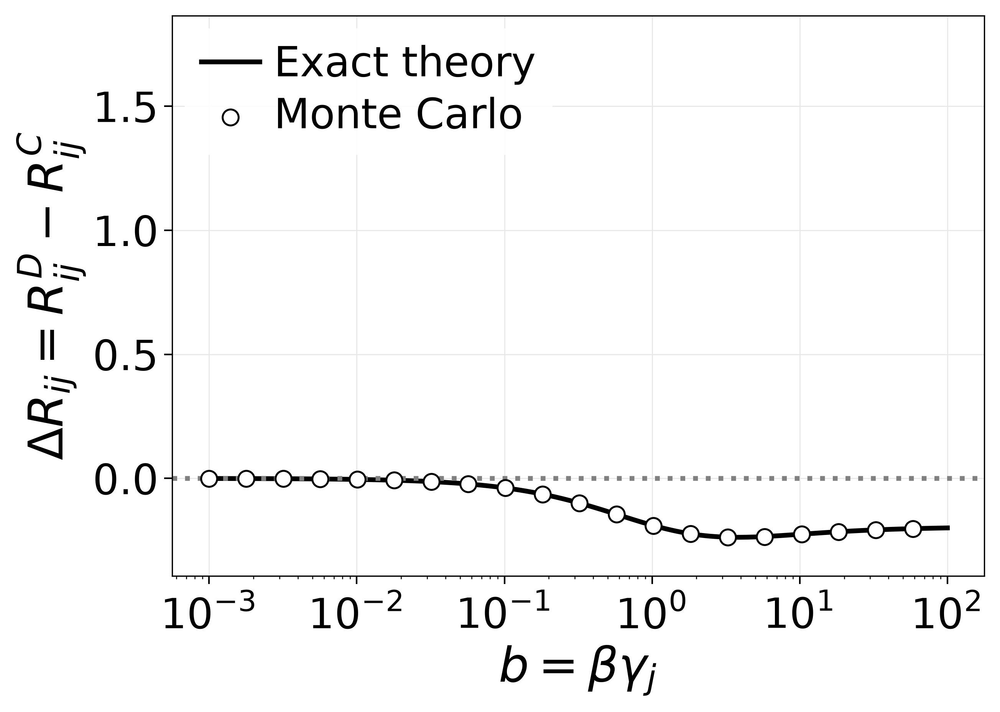

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_low


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_low')

In [6]:
plot_synthetic('low')


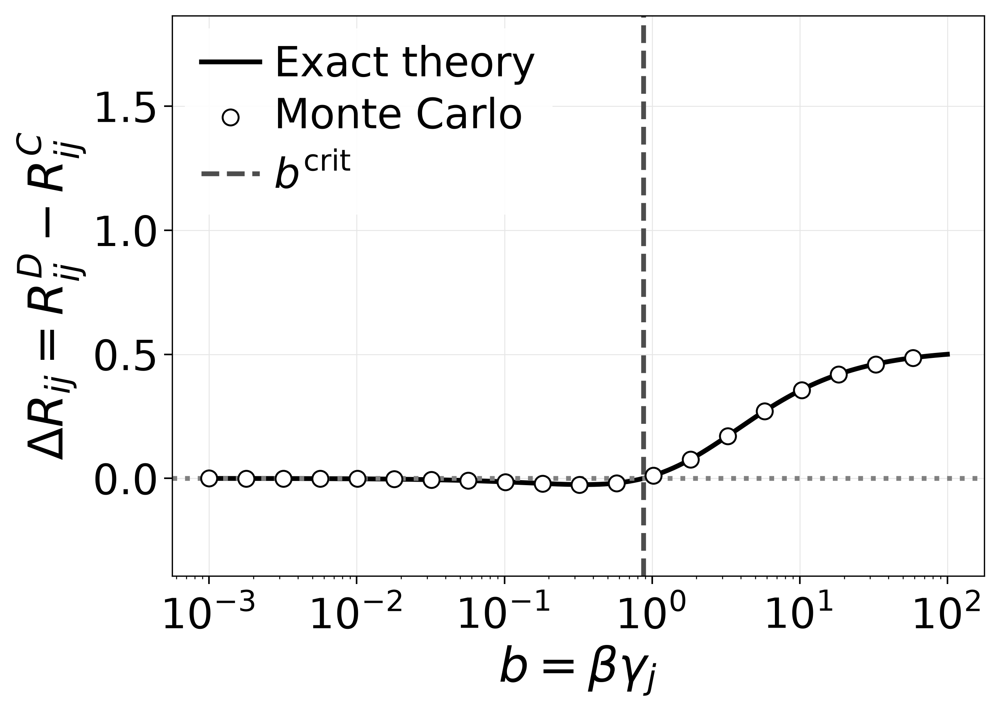

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_intermediate


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_intermediate')

In [7]:
plot_synthetic('intermediate')


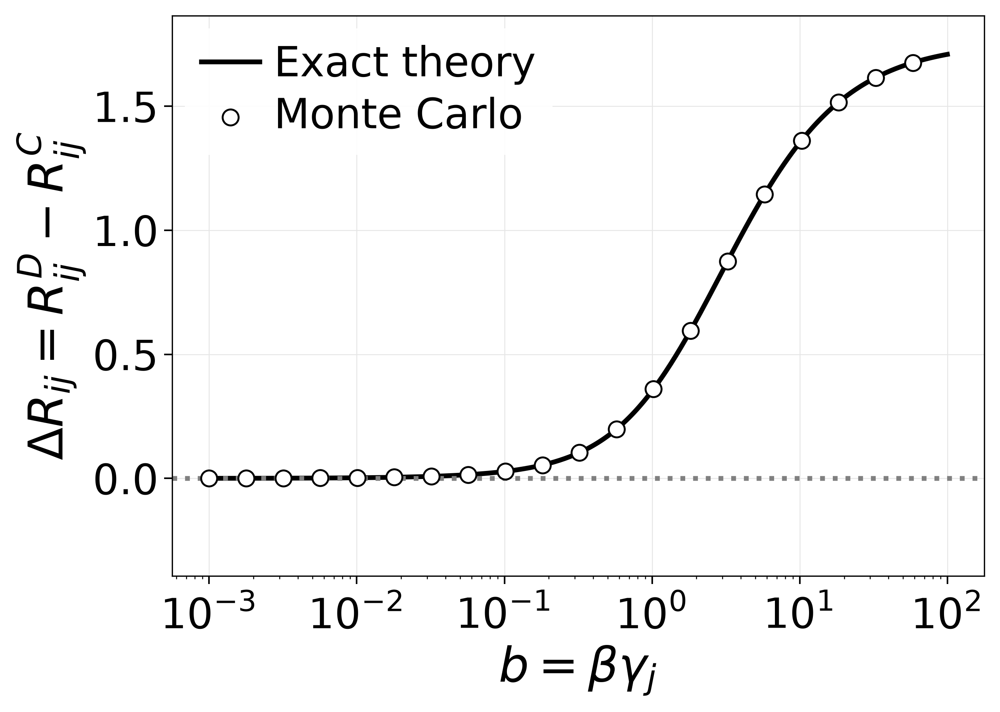

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_high


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Synthetic_high')

In [8]:
plot_synthetic('high')


In [ ]:
F1 = read_figure_csv('Figure1_all_context_effects.csv')
F2 = read_figure_csv('Figure2_all_null_raw.csv')
F3 = read_figure_csv('Figure3_paired_seed_effects.csv')
AUDITS = read_figure_csv('all_method_seed_scores_and_audits.csv')
F4 = read_figure_csv('Figure4_context_effect_points.csv')


def validate_plot_data():
    metrics = {'mean_poisson_deviance', 'normalized_mse'}
    reps = {'replicate_1', 'replicate_2'}
    roster = set(map(tuple, context_key(F1).to_numpy()))
    if len(roster) != 15: raise ValueError('需要全部 15 个 contexts')
    for frame in [F1,F2,F3,F4,AUDITS]:
        if set(map(tuple,context_key(frame).to_numpy())) != roster:
            raise ValueError('图源 contexts 不一致')
    for frame in [F1,F2,F3,F4]:
        if set(frame.metric) != metrics: raise ValueError('主次指标不齐全')
    for metric in sorted(metrics):
        for context in sorted(roster):
            line, drug = context
            for rep in sorted(reps):
                scope = lambda frame: frame[frame.cell_line.eq(line) & frame.drug.eq(drug) & frame.replicate.eq(rep)]
                a = scope(F1); a=a[a.metric.eq(metric)]
                if len(a)!=3 or set(a.method)!={'M0','M1','M2'}: raise ValueError('F1 coverage')
                base=float(a[a.method.eq('M0')].loss.iloc[0])
                finite_values(a.loss,'F1 loss')
                if base <= 0: raise ValueError('M0=0：相对效应未定义，不能画相对 panel')
                np.testing.assert_allclose(a.percent_vs_M0,100*(a.loss-base)/base,atol=1e-10)
                for frame, col in [(F2,'plot_percent_M4_minus_M1'),(F3,'percent_M2_minus_M3')]:
                    g=scope(frame);g=g[g.metric.eq(metric)]
                    check_seeds(g,col);finite_values(g[col],col)
                    if frame is F2:
                        expected=100*(g.M4_score-g.M1_score)/g.M1_score
                    else: expected=100*(g.M2_score-g.M3_score)/g.M3_score
                    np.testing.assert_allclose(g[col],expected,atol=1e-10)
            for comparison in ['fixed','adaptive']:
                g=F4[F4.cell_line.eq(line)&F4.drug.eq(drug)&F4.metric.eq(metric)&F4.comparison.eq(comparison)]
                if len(g)!=1: raise ValueError('F4 coverage')
                if not set(g.band_class) <= set(PLOT['class_style']): raise ValueError('未知 F4 分类')
                finite_values(g[['percent_label_1','percent_label_2']],'F4 points')
    if len(F1)!=180 or len(F2)!=1200 or len(F3)!=1200 or len(F4)!=60 or len(AUDITS)!=1290:
        raise ValueError('图源行数不符；不能静默忽略额外或缺失数据')
    for (line,drug,rep), g in AUDITS.groupby(['cell_line','drug','replicate']):
        if rep not in reps or set(g.method)!={'M0','M1','M2','M3','M4'}:
            raise ValueError('AUDITS roster')
        for method in ['M0','M1','M2']:
            if len(g[g.method.eq(method)]) != 1: raise ValueError('AUDITS deterministic duplicates')
        for method in ['M3','M4']: check_seeds(g[g.method.eq(method)],'AUDITS '+method)
        finite_values(g[['zero_weight_edge_fraction','weight_sum',
                         'beta_times_gene_lambda_max','conditional_trace_H']],'graph audits')
    print('图源数据完整性及差值公式检查通过。')

validate_plot_data()
print('保存目录：', OUTPUT_DIR)
CONTEXT_KEY = F4[['context_id','cell_line','drug']].drop_duplicates().sort_values('context_id')
print(CONTEXT_KEY.to_string(index=False))


图源数据完整性及差值公式检查通过。
保存目录： /home/featurize/work/biological_prior_validation/YifengMu_Figures
 context_id cell_line       drug
          1      A172  Lapatinib
          2      A172 Nintedanib
          3      A172 Trametinib
          4      A172    Vehicle
          5      A172    ZSTK474
          6      T98G  Lapatinib
          7      T98G Nintedanib
          8      T98G Trametinib
          9      T98G    Vehicle
         10      T98G    ZSTK474
         11     U87MG  Lapatinib
         12     U87MG Nintedanib
         13     U87MG Trametinib
         14     U87MG    Vehicle
         15     U87MG    ZSTK474


In [ ]:
def draw_figure1(ax, metric, rep, effect, p, *, ylabel=True):
    suffix = 'primary' if metric == 'mean_poisson_deviance' else 'secondary'
    g = F1[F1.metric.eq(metric) & F1.replicate.eq(rep)]

    if g.empty:
        raise ValueError(f'Figure1 缺少 {metric} {rep}')

    mapping = context_axis(ax, g)

    for method in (['M1', 'M2'] if effect else ['M0', 'M1', 'M2']):
        m = g[g.method.eq(method)]

        if len(m) != len(mapping):
            raise ValueError('Figure1 某个 method 缺少 context')

        y = [
            mapping[(r.cell_line, r.drug)] + p['method_offsets'][method]
            for r in m.itertuples()
        ]

        st = p['method_style'][method]

        ax.scatter(
            finite_values(
                m.percent_vs_M0 if effect else m.loss,
                'Figure1'
            ),
            y,
            s=p['marker_size'],
            linewidths=p['edge_width'],
            label=method,
            **st,
            zorder=3
        )

    if effect:
        ax.axvline(
            0,
            color='0.4',
            linestyle=p['zero_style'],
            linewidth=p['line_width']
        )

    xlabel = (
        r'$100\,(D_{\mathrm{method}}-D_{M0})/D_{M0}$ (%)'
        if effect else
        (
            'Held-out Poisson deviance'
            if suffix == 'primary'
            else 'Held-out normalized MSE'
        )
    )

    style_axes(ax, p, xlabel)

    if not ylabel:
        ax.tick_params(axis='y', labelleft=False)

    ncol = 2 if effect else 3

    if p.get('figure1_legend_above_axes', False):
        legend = add_legend(
            ax,
            p,
            loc='lower left',
            ncol=ncol
        )

        legend.set_bbox_to_anchor(
            p.get('figure1_legend_anchor', (0.0, 1.015)),
            transform=ax.transAxes
        )

    else:
        legend = add_legend(
            ax,
            p,
            loc=p.get('figure1_legend_loc', 'upper right'),
            ncol=ncol
        )

    if p.get('figure1_legend_transparent', False):
        frame = legend.get_frame()
        frame.set_facecolor('none')
        frame.set_edgecolor('none')
        frame.set_alpha(0.0)

    return ax


def plot_figure1(metric, rep, effect=False):
    suffix = 'primary' if metric == 'mean_poisson_deviance' else 'secondary'
    name = f"Figure1_{suffix}_{'effect' if effect else 'loss'}_{rep}"
    fig, ax, p = new_panel(name)
    draw_figure1(ax,metric,rep,effect,p)
    return finish_panel(fig,name,p)


def plot_figure1_combined(metric='mean_poisson_deviance'):
    """Four panels (loss × replicate labels / effect × replicate labels)."""
    suffix = 'primary' if metric == 'mean_poisson_deviance' else 'secondary'
    name = f'Figure1_{suffix}_all'
    fig, axes, p = new_composite(name, 'context', 2, 2)
    for row, effect in enumerate((False,True)):
        for col, rep in enumerate(('replicate_1','replicate_2')):
            ax = axes[row,col]
            draw_figure1(ax,metric,rep,effect,p,ylabel=(col==0))
            ax.set_title(rep.replace('_',' ') + (' · effect' if effect else ' · loss'),
                         fontsize=p.get('panel_title_size',p['labelsize']),pad=5)
    return finish_panel(fig, f'Figure1_all_context_effects_{suffix}',p)


def format_parameter(x):
    """≥0.01: fixed two decimals; smaller nonzero parameters: 2-decimal scientific.

    Do NOT turn a small but nonzero α/β into an artificial zero.
    """
    x = float(x)
    if not np.isfinite(x):
        raise ValueError('不允许显示 NaN/inf 参数')
    if x == 0:
        return '0.00'
    if abs(x) >= 0.01:
        return f'{x:.2f}'
    return f'{x:.2e}'


def _parameter_annotation(ax, note, p):
    """Keep α/β note inside frame, away from the vertical x=0 dashed line.

    Try BOTH sides and successively smaller font sizes. If the dashed line
    leaves insufficient room on either side, opaque white backing separates
    the reference line from the text rather than allowing glyph collisions.
    """
    fig = ax.figure
    fig.canvas.draw()
    ref = ax.transData.transform((0,0))[0]
    box = ax.bbox
    left_space = ref-box.x0
    right_space = box.x1-ref
    candidates = [(0.018,'left'),(0.982,'right')]
    if right_space > left_space:
        candidates.reverse()
    best = None
    for size in (p['annotation_size'],max(7.0,p['annotation_size']-.75),
                 max(6.0,p['annotation_size']-1.5)):
        for x,ha in candidates:
            ann = ax.text(x, 0.985, note, transform=ax.transAxes,
                          fontsize=size, ha=ha, va='top', zorder=7,
                          linespacing=1.12,
                          bbox={'facecolor':'white','edgecolor':'none',
                                'alpha':0.94,'pad':1.2})
            rect = ann.get_window_extent(fig.canvas.get_renderer())
            inside = (rect.x0 >= box.x0 + 2 and rect.x1 <= box.x1 - 2
                      and rect.y0 >= box.y0 + 2 and rect.y1 <= box.y1 - 2)
            crosses = rect.x0 - 4 <= ref <= rect.x1 + 4
            if inside and not crosses:
                return ann
            if best is None and inside:
                best = (size,x,ha)
            ann.remove()
    if best is not None:
        size,x,ha = best
        return ax.text(x,0.985,note,transform=ax.transAxes,fontsize=size,
                       ha=ha,va='top',zorder=7,linespacing=1.12,
                       bbox={'facecolor':'white','edgecolor':'none','alpha':0.96,'pad':1.2})
    raise RuntimeError('Figure2 注释超出图框：请增大 combined_figsize 或减小 annotation_size')

def draw_figure2(ax, line, drug, rep, p,
                 metric='mean_poisson_deviance'):

    g = F2[
        F2.metric.eq(metric)
        & F2.cell_line.eq(line)
        & F2.drug.eq(drug)
        & F2.replicate.eq(rep)
    ].sort_values('seed_index')

    check_seeds(g, f'Figure2 / {line} / {drug} / {rep}')
    x = finite_values(g.plot_percent_M4_minus_M1, 'Figure2')

    import inspect
    orientation = (
        {'orientation': 'horizontal'}
        if 'orientation' in inspect.signature(ax.boxplot).parameters
        else {'vert': False}
    )

    ax.boxplot(
        [x], **orientation,
        positions=[0],
        widths=.18,
        whis=(0, 100),
        showfliers=False,
        patch_artist=True,
        boxprops={
            'facecolor': p['null_face'],
            'edgecolor': 'black',
            'hatch': p['null_hatch']
        },
        medianprops={
            'color': 'black',
            'linewidth': p['line_width']
        },
        whiskerprops={'color': 'black'},
        capprops={'color': 'black'}
    )

    ax.scatter(
        x,
        p['null_jitter'] * np.sin(
            g.seed_index.to_numpy() * 2.399963
        ),
        marker='o',
        s=p['marker_size'],
        facecolors='white',
        edgecolors='black',
        linewidths=p['edge_width'],
        zorder=4
    )

    ax.axvline(
        0,
        color='0.35',
        linestyle='--',
        linewidth=p['line_width'],
        zorder=2
    )

    if np.ptp(x) == 0:
        v = float(x[0])
        pad = max(abs(v) * .1, 1e-5)
        ax.set_xlim(min(v, 0.0)-pad, max(v, 0.0)+pad)
    else:
        ll = min(float(x.min()), 0.0)
        rr = max(float(x.max()), 0.0)
        pad = max((rr-ll) * .055, 1e-9)
        ax.set_xlim(ll-pad, rr+pad)

    ax.set_yticks([])

    ax.set_ylim(
        p.get('figure2_ylim_bottom', -.31),
        .46 if p['show_null_parameter_note'] else .31
    )

    style_axes(
        ax, p,
        r'$100\,(D_{M4}-D_{M1})/D_{M1}$ (%)'
    )

    if p['show_null_parameter_note']:
        r = g.iloc[0]

        note = (
            f'M1: loss={format_parameter(r.M1_score)}, '
            f'α={format_parameter(r.M1_alpha)}, '
            f'β={format_parameter(r.M1_beta)}\n'
            f'M4 α: [{format_parameter(g.M4_alpha.min())}, '
            f'{format_parameter(g.M4_alpha.max())}]\n'
            f'M4 β: [{format_parameter(g.M4_beta.min())}, '
            f'{format_parameter(g.M4_beta.max())}]'
        )

        _parameter_annotation(ax, note, p)

    handles = [
        Line2D(
            [0], [0],
            color='0.35',
            linestyle='--',
            linewidth=p['line_width'],
            label='Real M1 = 0'
        ),
        Line2D(
            [0], [0],
            marker='o',
            color='none',
            markerfacecolor='white',
            markeredgecolor='black',
            label='M4 seed'
        )
    ]

    lim = ax.get_xlim()
    zero = (0 - lim[0]) / (lim[1] - lim[0])

    legend_on_left = zero > 0.5
    legend_loc = (
        'lower left' if legend_on_left else 'lower right'
    )

    legend_ncol = int(p.get('figure2_legend_ncol', 2))

    if legend_ncol not in (1, 2):
        raise ValueError(
            'figure2_legend_ncol 只能为 1 或 2'
        )

    legend = add_legend(
        ax,
        p,
        handles,
        loc=legend_loc,
        ncol=legend_ncol
    )

    legend_y = float(
        p.get('figure2_legend_y', 0.01)
    )

    legend_margin_x = float(
        p.get('figure2_legend_x_margin', 0.015)
    )

    if not (0 <= legend_y <= 0.2):
        raise ValueError(
            'figure2_legend_y 须在 [0, 0.2] 内'
        )

    if not (0 <= legend_margin_x <= 0.2):
        raise ValueError(
            'figure2_legend_x_margin 须在 [0, 0.2] 内'
        )

    legend.borderaxespad = 0.0

    legend_x = (
        legend_margin_x
        if legend_on_left
        else 1 - legend_margin_x
    )

    legend.set_bbox_to_anchor(
        (legend_x, legend_y),
        transform=ax.transAxes
    )

    if p.get('figure2_legend_transparent', False):
        legend.get_frame().set_visible(False)

    return ax

def _figure2_fixed_layout(fig, p, *, combined):
    """Figure 2 专用固定布局：统一八张图的绘图区，不改变各图的数据 xlim。"""
    fig.set_layout_engine(None)  # 关闭 constrained_layout 的逐图自动调整

    margin_key = (
        'figure2_combined_margins' if combined
        else 'figure2_single_margins'
    )
    left, right, bottom, top = map(float, p[margin_key])
    if not (0 < left < right < 1 and 0 < bottom < top < 1):
        raise ValueError(f'{margin_key} 必须满足 0 < left < right < 1 和 0 < bottom < top < 1')

    kwargs = dict(left=left, right=right, bottom=bottom, top=top)
    if combined:
        wspace = float(p.get('figure2_wspace', 0.24))
        hspace = float(p.get('figure2_hspace', 0.55))
        if wspace < 0 or hspace < 0:
            raise ValueError('Figure2 子图间距不能为负')
        kwargs.update(wspace=wspace, hspace=hspace)
    fig.subplots_adjust(**kwargs)


def plot_figure2(line, drug, rep, metric='mean_poisson_deviance'):
    suffix = 'primary' if metric == 'mean_poisson_deviance' else 'secondary'
    name = f'Figure2_{suffix}_{line}_{drug}_{rep}'
    fig, ax, p = new_panel(name, 'null')
    _figure2_fixed_layout(fig, p, combined=False)
    draw_figure2(ax, line, drug, rep, p, metric=metric)
    return finish_panel(fig, name, p)


def plot_figure2_combined():
    name = 'Figure2_primary_all'
    contexts = (
        ('A172', 'Lapatinib'),
        ('A172', 'Trametinib'),
        ('T98G', 'Nintedanib'),
        ('U87MG', 'ZSTK474'),
    )
    fig, axes, p = new_composite(name, 'null', 4, 2)
    _figure2_fixed_layout(fig, p, combined=True)

    for row, (line, drug) in enumerate(contexts):
        for col, rep in enumerate(('replicate_1', 'replicate_2')):
            ax = axes[row, col]
            draw_figure2(ax, line, drug, rep, p)
            ax.set_title(
                f'{line} / {drug} | {rep}',
                fontsize=p.get('panel_title_size', p['labelsize']),
                pad=p.get('figure2_title_pad', 7)
            )
            if p.get('figure2_panel_letters', False):
                ax.text(
                    -0.025, 1.015, chr(ord('A') + 2 * row + col),
                    transform=ax.transAxes, ha='right', va='bottom',
                    fontweight='bold',
                    fontsize=p.get('figure2_panel_letter_size', 19),
                    clip_on=False,
                )

    return finish_panel(fig, 'Figure2_PPI_identity_primary', p)

def draw_figure3(ax, quantity, p, *, ylabel=True):
    quantities = {
        'paired_effect': (
            'Paired M2 − M3 (% of each M3)', None
        ),
        'zero_fraction': (
            'Zero-weight edge fraction',
            'zero_weight_edge_fraction'
        ),
        'weight_sum': (
            'Total edge weight',
            'weight_sum'
        ),
        'gene_scale': (
            r'$\beta\,\lambda_{\max}(L_g)$',
            'beta_times_gene_lambda_max'
        ),
        'conditional_EDF': (
            r'Conditional EDF: $\mathrm{tr}(H)$',
            'conditional_trace_H'
        ),
    }

    if quantity not in quantities:
        raise ValueError('未知 Figure3 quantity')

    label, column = quantities[quantity]
    pairs = F3[F3.metric.eq('mean_poisson_deviance')]
    mapping = context_axis(ax, pairs)

    rep_offsets = p.get(
        'figure3_replicate_offsets',
        p['replicate_offsets']
    )
    model_offset = float(
        p.get('figure3_model_offset', p['model_offset'])
    )
    audit_area = float(
        p.get('figure3_audit_marker_size', p['marker_size'])
    )
    circle_area = float(
    p.get('figure3_audit_circle_size', audit_area)
    )
    diamond_area = float(
    p.get('figure3_audit_diamond_size', audit_area)
    )
    paired_area = float(
        p.get('figure3_paired_marker_size', p['marker_size'])
    )
    audit_edge_width = float(
        p.get('figure3_audit_edge_width', p['edge_width'])
    )

    audit_area = float(p.get('figure3_audit_marker_size', p['marker_size']))
    circle_area = float(p.get('figure3_audit_circle_size', audit_area))
    diamond_area = float(p.get('figure3_audit_diamond_size', audit_area))
    paired_area = float(p.get('figure3_paired_marker_size', p['marker_size']))
    audit_edge_width = float(p.get('figure3_audit_edge_width', p['edge_width']))

    if min(
        audit_area,
        circle_area,
        diamond_area,
        paired_area
    ) <= 0 or audit_edge_width < 0:
        raise ValueError('Figure3 散点面积须正，边框宽度须非负')

    paired_range = p.get('figure3_paired_quantiles', (0.05, 0.95))
    audit_range = p.get('figure3_audit_quantiles', (0.05, 0.95))
    
    paired_range = p.get(
        'figure3_paired_quantiles', (0.05, 0.95)
    )
    audit_range = p.get(
        'figure3_audit_quantiles', (0.05, 0.95)
    )

    for q in (paired_range, audit_range):
        if len(q) != 2 or not (0 <= q[0] < q[1] <= 1):
            raise ValueError(
                'Figure 3 quantiles 须满足 0 <= low < high <= 1'
            )

    if audit_area <= 0 or paired_area <= 0 or audit_edge_width < 0:
        raise ValueError(
            'Figure3 散点面积须正，边框宽度须非负'
        )

    if model_offset < 0:
        raise ValueError('Figure3 model_offset 不能为负')

    if set(rep_offsets) != {'replicate_1', 'replicate_2'}:
        raise ValueError(
            'Figure3 replicate_offsets 必须包含两次 replicate'
        )

    for rep in ('replicate_1', 'replicate_2'):
        st = p['replicate_style'][rep]

        for (line, drug), g in pairs[
            pairs.replicate.eq(rep)
        ].groupby(['cell_line', 'drug']):

            check_seeds(g, 'Figure3')

            y = (
                mapping[(line, drug)]
                + rep_offsets[rep]
            )

            if column is None:
                x = finite_values(
                    g.percent_M2_minus_M3,
                    'Figure3 paired'
                )

                ax.plot(
                    np.quantile(x, paired_range),
                    [y, y],
                    color='black',
                    linestyle=st['linestyle'],
                    linewidth=p['line_width'],
                    zorder=2
                )

                ax.scatter(
                    float(x.mean()),
                    y,
                    marker='o',
                    s=paired_area,
                    facecolors=st['facecolor'],
                    edgecolors='black',
                    linewidths=p['edge_width'],
                    zorder=4
                )

            else:
                a = AUDITS[
                    AUDITS.cell_line.eq(line)
                    & AUDITS.drug.eq(drug)
                    & AUDITS.replicate.eq(rep)
                ]

                m2 = a[a.method.eq('M2')]
                m3 = a[a.method.eq('M3')]

                if len(m2) != 1:
                    raise ValueError('M2 audit 必须唯一')

                check_seeds(m3, 'Figure3 M3 audit')

                x = finite_values(
                    m3[column],
                    'Figure3 audit'
                )

                dy = model_offset

                ax.plot(
                    np.quantile(x, audit_range),
                    [y + dy, y + dy],
                    color='black',
                    linestyle=st['linestyle'],
                    linewidth=p['line_width'],
                    zorder=2
                )

                for val, yy, marker, size in (
                    (float(x.mean()), y + dy, 'D', diamond_area),
                    (float(m2[column].iloc[0]), y - dy, 'o', circle_area)
                ):
                    ax.scatter(
                        val,
                        yy,
                        marker=marker,
                        s=size,
                        facecolors=st['facecolor'],
                        edgecolors='black',
                        linewidths=audit_edge_width,
                        zorder=4
                    )

    if quantity == 'paired_effect':
        ax.axvline(
            0,
            color='0.4',
            linestyle=p['zero_style'],
            linewidth=p['line_width']
        )

    if quantity == 'zero_fraction':
        ax.set_xlim(-.02, 1.02)

    style_axes(ax, p, label)

    if not ylabel:
        ax.tick_params(axis='y', labelleft=False)

    return ax


def plot_figure3(quantity):
    name='Figure3_primary_'+quantity
    fig,ax,p=new_panel(name)
    draw_figure3(ax,quantity,p)
    return finish_panel(fig,name,p)


def plot_figure3_combined():
    """Five panels; last row uses the full width. Legend is in TeX caption."""
    name='Figure3_primary_all'
    p=config(name,'context')
    p['figsize']=tuple(p.get('combined_figsize',p['figsize']))
    with plt.rc_context({'font.family':p['font_family'],'svg.fonttype':'none','pdf.fonttype':42}):
        fig=plt.figure(figsize=p['figsize'],dpi=p['display_dpi'],layout='constrained')
        gs=fig.add_gridspec(3,2)
        axes=[fig.add_subplot(gs[0,0]),fig.add_subplot(gs[0,1]),
              fig.add_subplot(gs[1,0]),fig.add_subplot(gs[1,1]),
              fig.add_subplot(gs[2,:])]
    for ax,quantity in zip(axes,('paired_effect','zero_fraction','weight_sum',
                                 'gene_scale','conditional_EDF')):
        draw_figure3(ax,quantity,p)
        ax.set_title(quantity.replace('_',' ').title(),
                     fontsize=p.get('panel_title_size',p['labelsize']),pad=4)
    return finish_panel(fig,'Figure3_adaptive_attenuation_primary',p)

def context_key_from_points():
    key=F4[['context_id','cell_line','drug']].drop_duplicates().sort_values('context_id')
    if len(key)!=15 or set(key.context_id)!=set(range(1,16)):
        raise ValueError('Figure4 CONTEXT KEY 应有 1–15，且不得缺失')
    return key

def draw_context_key(ax, p, handles=None):
    """上方 CONTEXT KEY，下方独立的符号图例。"""
    ax.set_axis_off()

    legend_ax = getattr(ax, '_figure4_legend_ax', None)
    if legend_ax is None:
        raise RuntimeError(
            '请先运行新版 _new_figure4_layout()'
        )

    legend_ax.set_axis_off()

    key = context_key_from_points()

    key_size = float(
        p.get('context_key_size', p['annotation_size'])
    )
    legend_size = float(p.get('legend_size', 16))
    line_spacing = float(
        p.get('figure4_key_linespacing', 1.12)
    )

    if key_size <= 0 or legend_size <= 0:
        raise ValueError('字体大小必须为正数')

    if not 0.9 <= line_spacing <= 1.7:
        raise ValueError(
            'figure4_key_linespacing 应在 0.9–1.7 之间'
        )

    key_text = '\n'.join(
        f'{int(row.context_id):>2}  '
        f'{row.cell_line} / {row.drug}'
        for row in key.itertuples()
    )

    title = ax.text(
        0.025, 0.985,
        'CONTEXT KEY',
        transform=ax.transAxes,
        ha='left',
        va='top',
        fontsize=key_size + 1,
        family=p['font_family']
    )

    body = ax.annotate(
        key_text,
        xy=(0.025, 0.985),
        xycoords=ax.transAxes,
        xytext=(0, -1.75 * key_size),
        textcoords='offset points',
        ha='left',
        va='top',
        fontsize=key_size,
        linespacing=line_spacing,
        family=p['font_family']
    )

    legend = None
    if handles:
        legend = legend_ax.legend(
            handles=handles,
            loc='upper left',
            bbox_to_anchor=(0.025, 0.98),
            fontsize=legend_size,
            frameon=False,
            handletextpad=0.45,
            borderaxespad=0,
            labelspacing=0.35
        )

    ax._figure4_key_title = title
    ax._figure4_key_body = body
    ax._figure4_key_legend = legend

    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()

    title_box = title.get_window_extent(renderer)
    body_box = body.get_window_extent(renderer)

    if title_box.y0 <= body_box.y1:
        raise RuntimeError(
            'CONTEXT KEY 标题与正文过近，请增大画幅高度'
        )

    if (
        body_box.y0 < ax.bbox.y0 + 2
        or body_box.x1 > ax.bbox.x1 + 2
    ):
        raise RuntimeError(
            'CONTEXT KEY 排不下，请增大 figsize '
            '或 context_key_width'
        )

    if legend is not None:
        legend_box = legend.get_window_extent(renderer)

        if (
            body_box.y0 <= legend_box.y1 + 6
            or legend_box.y0 < legend_ax.bbox.y0 - 2
            or legend_box.x1 > legend_ax.bbox.x1 + 2
        ):
            raise RuntimeError(
                'CONTEXT KEY 与图例空间不足，'
                '请增大画幅高度'
            )

def annotate_contexts(fig,ax,g,p):
    """Leader labels without changing coordinates. Only VISIBLE rows supplied."""
    if g.empty:
        return []
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    occupied=[]; factor=fig.dpi/72
    dots=ax.transData.transform(g[['percent_label_1','percent_label_2']].to_numpy(float))
    marker_radius=(np.sqrt(p['marker_size'])/2+1.5)*factor
    labels=[]
    for r in g.itertuples():
        txt=str(r.context_id)
        test=ax.text(0,0,txt,fontsize=p['annotation_size'])
        bounds=test.get_window_extent(renderer);test.remove()
        w,h=bounds.width+3*factor,bounds.height+2*factor
        px,py=ax.transData.transform((r.percent_label_1,r.percent_label_2))
        chosen=None
        for radius in p['context_label_radius']:
            for angle in np.linspace(0,2*np.pi,32,endpoint=False):
                dx,dy=radius*np.cos(angle),radius*np.sin(angle)
                cx,cy=px+dx*factor,py+dy*factor
                rect=(cx-w/2,cy-h/2,cx+w/2,cy+h/2)
                inside=(rect[0]>ax.bbox.x0+3 and rect[1]>ax.bbox.y0+3 and
                        rect[2]<ax.bbox.x1-3 and rect[3]<ax.bbox.y1-3)
                collides=any(not (rect[2]<b[0] or rect[0]>b[2] or
                                  rect[3]<b[1] or rect[1]>b[3]) for b in occupied)
                dot_hit=any(rect[0]-marker_radius<x<rect[2]+marker_radius and
                            rect[1]-marker_radius<y<rect[3]+marker_radius for x,y in dots)
                if inside and not collides and not dot_hit:
                    chosen=(dx,dy,rect)
                    break
            if chosen is not None:
                break
        if chosen is None:
            raise RuntimeError('Figure4 标签排不开：请增大 combined_figsize，或减小 annotation_size')
        dx,dy,rect=chosen
        occupied.append(rect)
        ann=ax.annotate(txt,(r.percent_label_1,r.percent_label_2),xytext=(dx,dy),
                        textcoords='offset points',ha='center',va='center',
                        fontsize=p['annotation_size'],zorder=5,
                        arrowprops={'arrowstyle':'-','color':'0.52','lw':.65})
        labels.append(ann)
    return labels

def draw_figure4(ax, comparison, p):
    g = F4[
        F4.metric.eq('mean_poisson_deviance') &
        F4.comparison.eq(comparison)
    ].sort_values('context_id')

    if len(g) != 15:
        raise ValueError('Figure4 必须含原始全部 15 contexts')

    values = finite_values(
        g[['percent_label_1', 'percent_label_2']],
        'Figure4'
    )
    band = float(g.near_zero_percent.iloc[0])

    if comparison == 'adaptive':
        lim = p['adaptive_limits']
        xmin, xmax = lim
        ymin, ymax = lim

        # 只在绘图时省略 context 5
        g_visible = g[g.context_id.ne(5)].copy()

        outside = g_visible[
            (g_visible.percent_label_1 < xmin) |
            (g_visible.percent_label_1 > xmax) |
            (g_visible.percent_label_2 < ymin) |
            (g_visible.percent_label_2 > ymax)
        ]

        if not outside.empty:
            raise ValueError(
                f'非 5 号点也超出 adaptive zoom: '
                f'{outside.context_id.tolist()}'
            )

        lo, hi = lim

    elif comparison == 'fixed':
        lo = min(float(values.min()), 0.)
        hi = max(float(values.max()), 0.)

        span = max(hi - lo, 4 * band, 1e-5)

        lo -= .20 * span
        hi += .20 * span

        g_visible = g.copy()

    else:
        raise ValueError('comparison 只能是 fixed/adaptive')
=
    ax.axvspan(-band, band, color='0.94', zorder=0)
    ax.axhspan(-band, band, color='0.94', zorder=0)

    ax.axvline(
        0, color='0.50',
        linewidth=1, zorder=1
    )

    ax.axhline(
        0, color='0.50',
        linewidth=1, zorder=1
    )

    ax.plot(
        [lo, hi],
        [lo, hi],
        color='0.55',
        linestyle=p['identity_style'],
        linewidth=1,
        zorder=1
    )


    handles = []

    for category, st in p['class_style'].items():
        m = g_visible[g_visible.band_class.eq(category)]

        ax.scatter(
            m.percent_label_1,
            m.percent_label_2,
            marker=st['marker'],
            s=p['marker_size'],
            facecolors=st['facecolor'],
            edgecolors='black',
            linewidths=p['edge_width'],
            zorder=3
        )

        handles.append(
            Line2D(
                [0], [0],
                marker=st['marker'],
                color='none',
                markerfacecolor=st['facecolor'],
                markeredgecolor='black',
                label=category.replace('_', ' ')
            )
        )


    ax.set(
        xlim=(lo, hi),
        ylim=(lo, hi)
    )

    ax.set_aspect('equal', adjustable='box')

    style_axes(
        ax,
        p,
        'replicate_1 effect (%)',
        'replicate_2 effect (%)',
        both_numeric=True
    )

  
    if comparison == 'adaptive':
        ax.set_xlim(p['adaptive_limits'])
        ax.set_ylim(p['adaptive_limits'])


    if p.get('figure4_plain_ticks', True):
        ax.ticklabel_format(
            style='plain',
            axis='both',
            useOffset=False
        )

    nbins = int(p.get('figure4_tick_nbins', 4))

    if nbins < 2:
        raise ValueError(
            'figure4_tick_nbins 必须至少为 2'
        )

    ax.xaxis.set_major_locator(
        MaxNLocator(nbins=nbins)
    )

    ax.yaxis.set_major_locator(
        MaxNLocator(nbins=nbins)
    )


    if comparison == 'adaptive':
        tick_count = int(
            p.get('figure4_adaptive_tick_count', 3)
        )

        if tick_count < 2:
            raise ValueError(
                'figure4_adaptive_tick_count 必须至少为 2'
            )

        lo, hi = p['adaptive_limits']
        ticks = np.linspace(lo, hi, tick_count)

        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

    labelpad = float(
        p.get('figure4_xlabel_pad', 18)
    )

    if labelpad < 0:
        raise ValueError(
            'figure4_xlabel_pad 不能为负'
        )

    ax.xaxis.labelpad = labelpad

    return g_visible, handles

def _new_figure4_layout(name, p, combined):
    p['figsize'] = (
        tuple(p.get('combined_figsize', p['figsize']))
        if combined else p['figsize']
    )

    key_height_share = float(
        p.get('figure4_key_height_share', 0.70)
    )

    if not 0.55 <= key_height_share <= 0.90:
        raise ValueError(
            'figure4_key_height_share 应在 0.55–0.90 之间'
        )

    with plt.rc_context({
        'font.family': p['font_family'],
        'svg.fonttype': 'none',
        'pdf.fonttype': 42
    }):
        fig = plt.figure(
            figsize=p['figsize'],
            dpi=p['display_dpi'],
            layout='constrained'
        )

        ncols = 3 if combined else 2

        widths = (
            [1, 1, p.get('context_key_width', 1.0)]
            if combined
            else [1, p.get('context_key_width', 1.0)]
        )

        gs = fig.add_gridspec(
            1,
            ncols,
            width_ratios=widths
        )

        axes = [
            fig.add_subplot(gs[0, index])
            for index in range(2 if combined else 1)
        ]

        # 散点图靠上对齐
        for data_ax in axes:
            data_ax.set_anchor('N')

        # 右侧分成 CONTEXT KEY 和图例两个区域
        right_gs = gs[0, -1].subgridspec(
            2,
            1,
            height_ratios=[
                key_height_share,
                1 - key_height_share
            ],
            hspace=0.06
        )

        key_ax = fig.add_subplot(right_gs[0, 0])
        legend_ax = fig.add_subplot(right_gs[1, 0])

        key_ax._figure4_legend_ax = legend_ax

    return fig, axes, key_ax


def plot_figure4(comparison):
    name='Figure4_primary_'+comparison
    p=config(name,'scatter')
    fig,axes,key_ax=_new_figure4_layout(name,p,combined=False)
    visible,handles=draw_figure4(axes[0],comparison,p)
    draw_context_key(key_ax,p,handles)
    fig.canvas.draw();fig.set_layout_engine(None)
    if p['show_context_numbers']:
        annotate_contexts(fig,axes[0],visible,p)
    return finish_panel(fig,name,p)


def plot_figure4_combined():
    name='Figure4_primary_all'
    p=config(name,'scatter')
    fig,axes,key_ax=_new_figure4_layout(name,p,combined=True)
    panels=[];handles=None
    for ax,comparison in zip(axes,('fixed','adaptive')):
        visible,handles=draw_figure4(ax,comparison,p)
        panels.append(visible)
        ax.set_title('M1 − M0' if comparison=='fixed' else 'M2 − M1 (zoom)',
                     fontsize=p.get('panel_title_size',p['labelsize']),pad=5)
    draw_context_key(key_ax,p,handles)
    fig.canvas.draw();fig.set_layout_engine(None)
    if p['show_context_numbers']:
        for ax,visible in zip(axes,panels):
            annotate_contexts(fig,ax,visible,p)
    return finish_panel(fig,'Figure4_label_consistency_primary',p)

In [ ]:
FIGURE1_PRIMARY_STYLE = dict(
    ticksize=24,
    labelsize=26,

    legend_size=16,
    annotation_size=9,
    panel_title_size=11,


    marker_size=100,
    edge_width=1.8,


    method_offsets={
        'M0': -0.33,   
        'M1':  0.00,   
        'M2':  0.33,   
    },

    figure1_legend_loc='upper left',
    figure1_legend_above_axes=False,
    figure1_legend_anchor=(0.0, 1.015),

    figsize=(10.5, 9.2),
    combined_figsize=(17.0, 19.0),
)

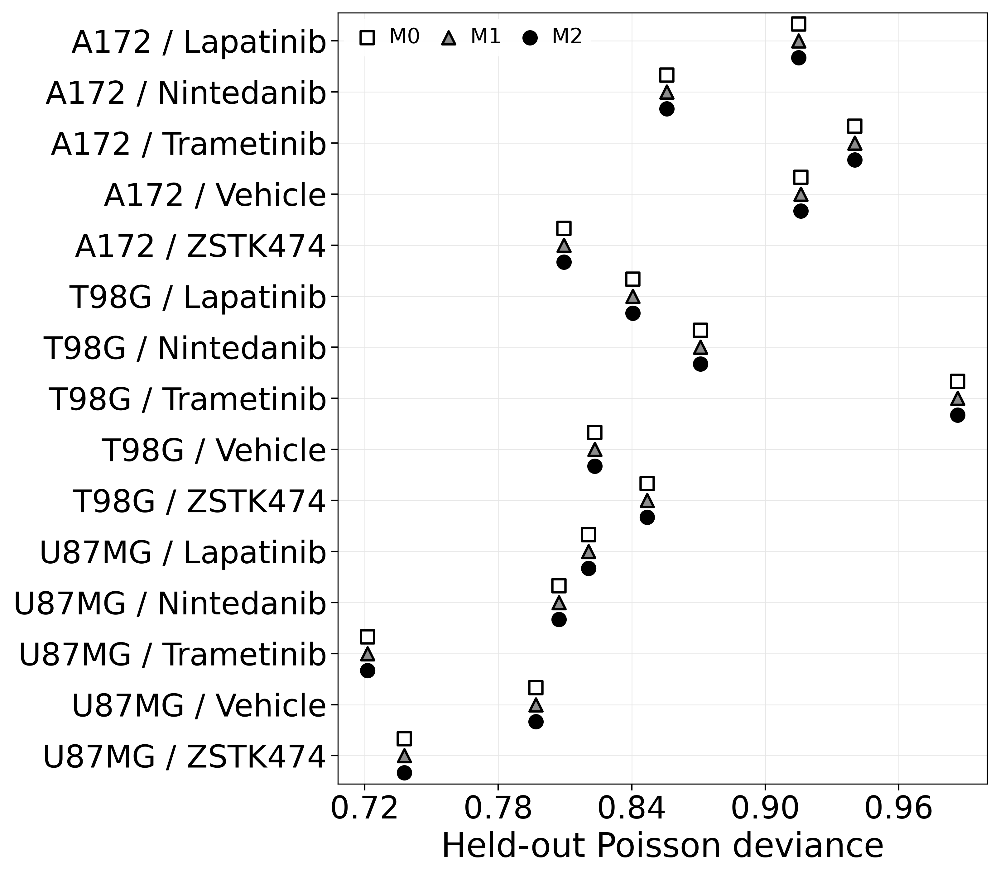

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_loss_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_loss_replicate_1')

In [13]:
plot_figure1('mean_poisson_deviance', 'replicate_1', effect=False)


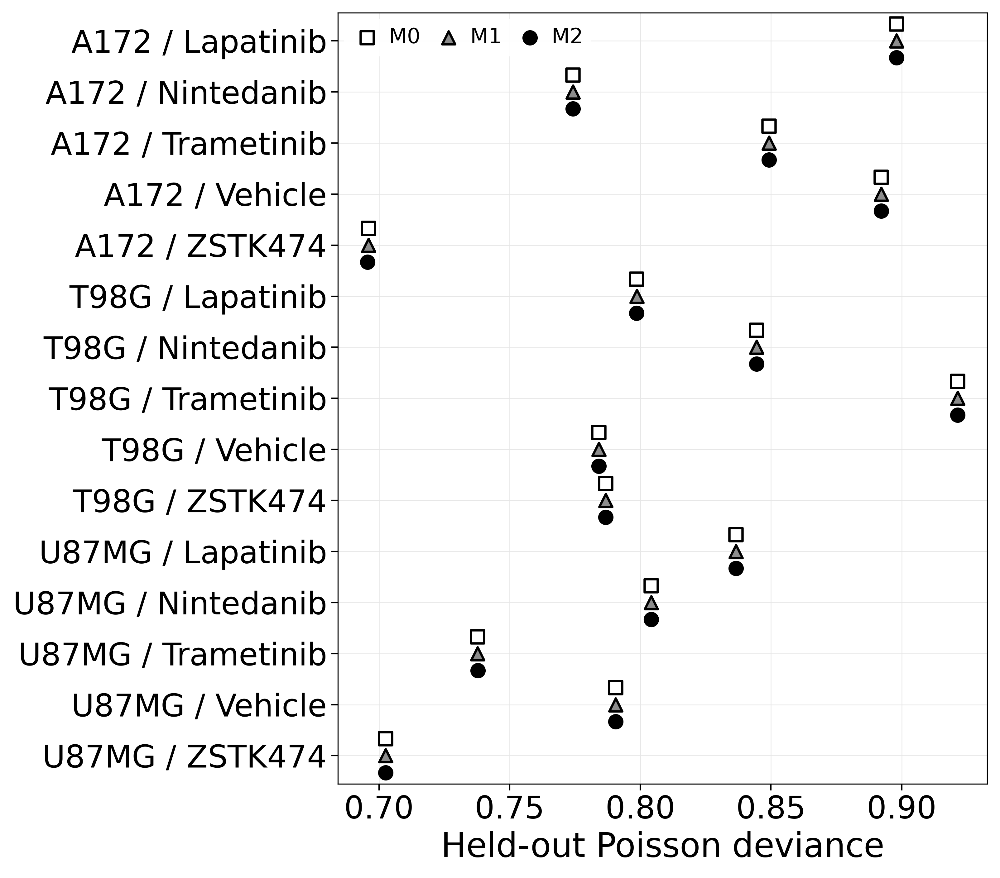

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_loss_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_loss_replicate_2')

In [14]:
plot_figure1('mean_poisson_deviance', 'replicate_2', effect=False)


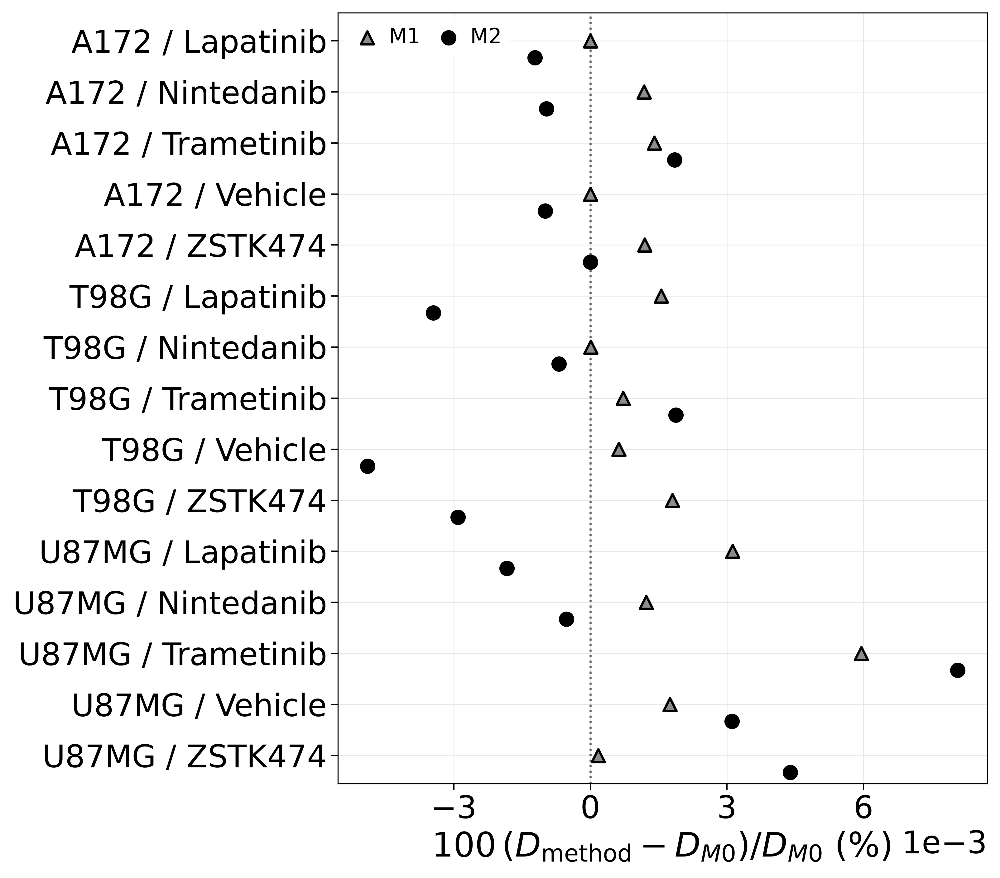

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_effect_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_effect_replicate_1')

In [15]:
plot_figure1('mean_poisson_deviance', 'replicate_1', effect=True)


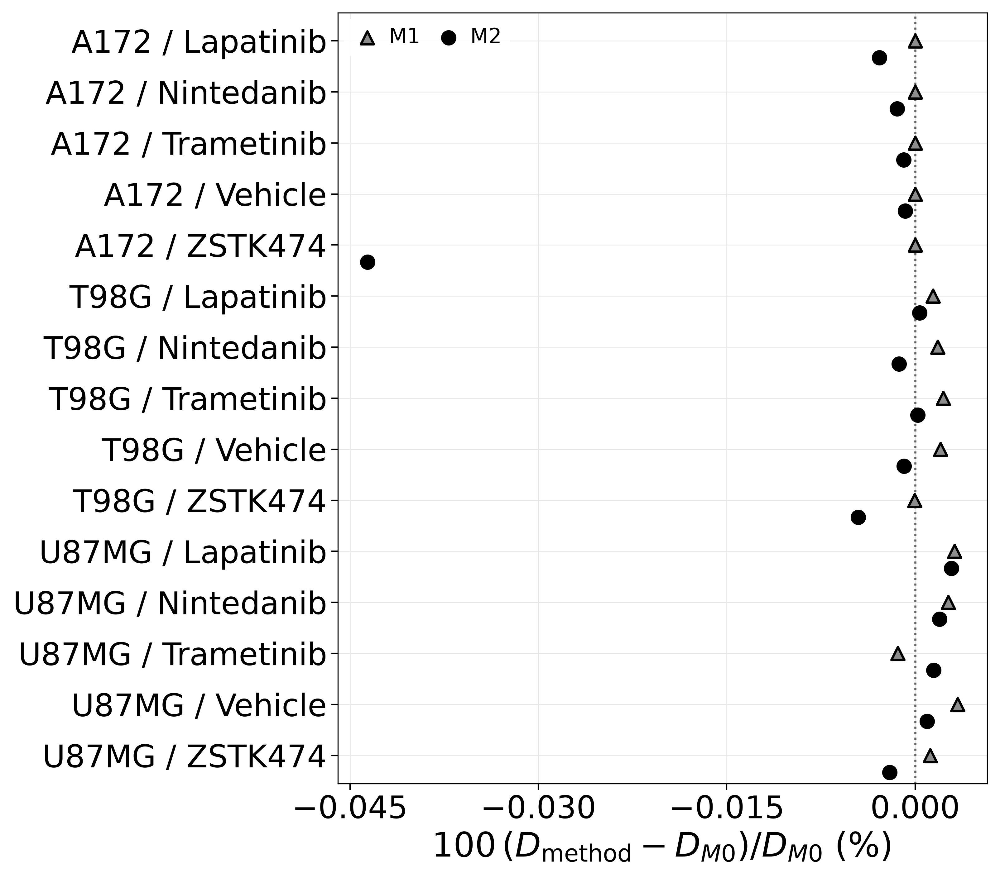

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_effect_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_primary_effect_replicate_2')

In [16]:
plot_figure1('mean_poisson_deviance', 'replicate_2', effect=True)


In [ ]:

FIGURE1_SECONDARY_STYLE = dict(
    ticksize=24,
    labelsize=26,

    legend_size=15,
    annotation_size=9,
    panel_title_size=11,

    marker_size=100,
    edge_width=1.8,

    method_offsets={
        'M0': -0.33,
        'M1':  0.00,
        'M2':  0.33,
    },

    figure1_legend_loc='upper right',
    figure1_legend_above_axes=False,
    figure1_legend_transparent=True,

    figsize=(10.5, 9.2),
    combined_figsize=(17.0, 19.0),
)

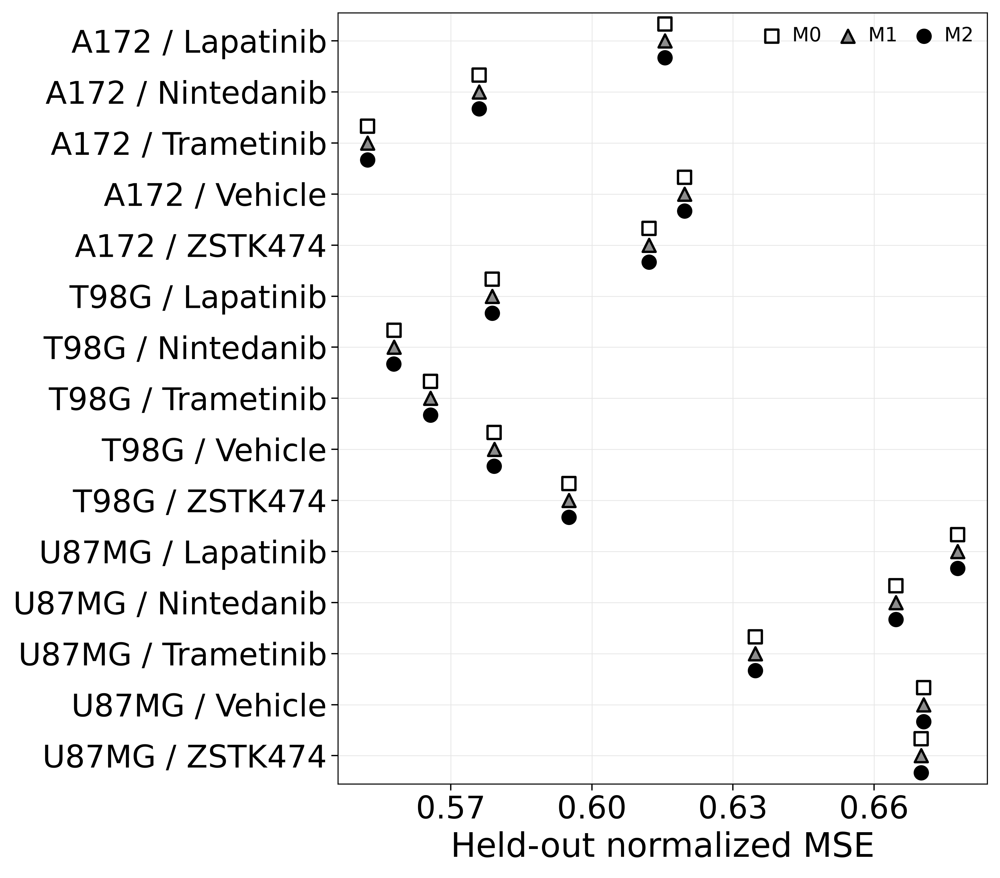

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_loss_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_loss_replicate_1')

In [19]:
plot_figure1('normalized_mse', 'replicate_1', effect=False)


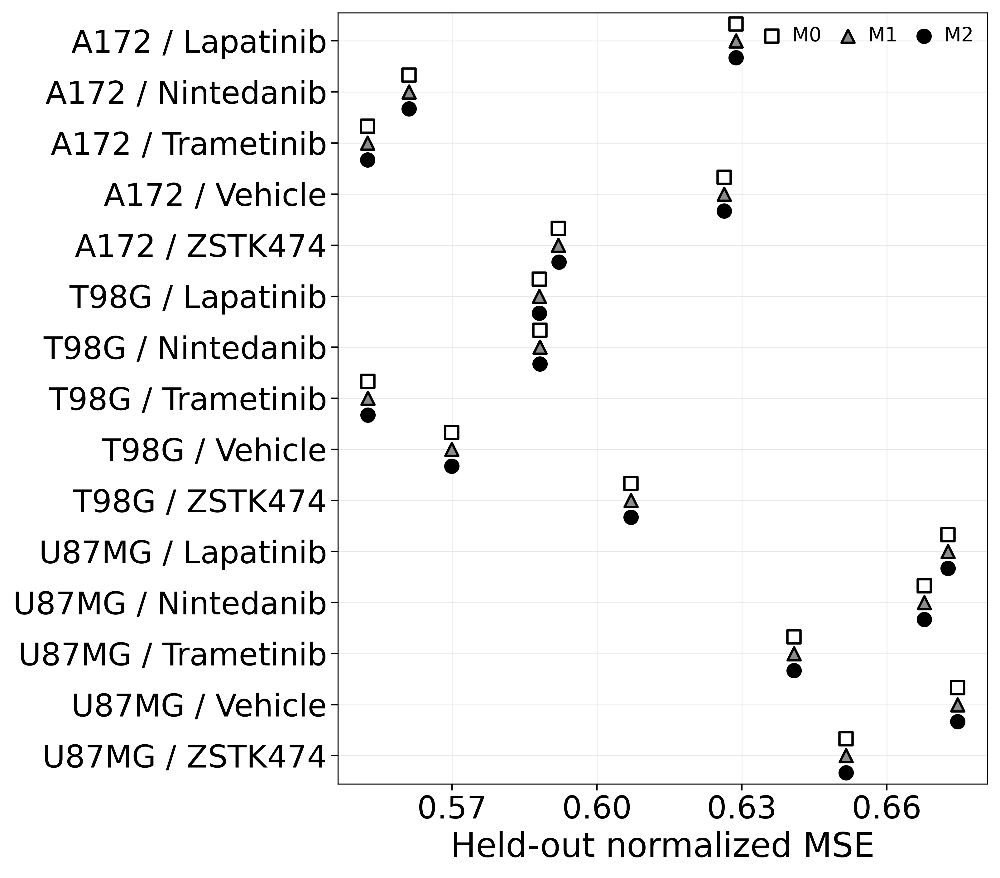

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_loss_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_loss_replicate_2')

In [20]:
plot_figure1('normalized_mse', 'replicate_2', effect=False)


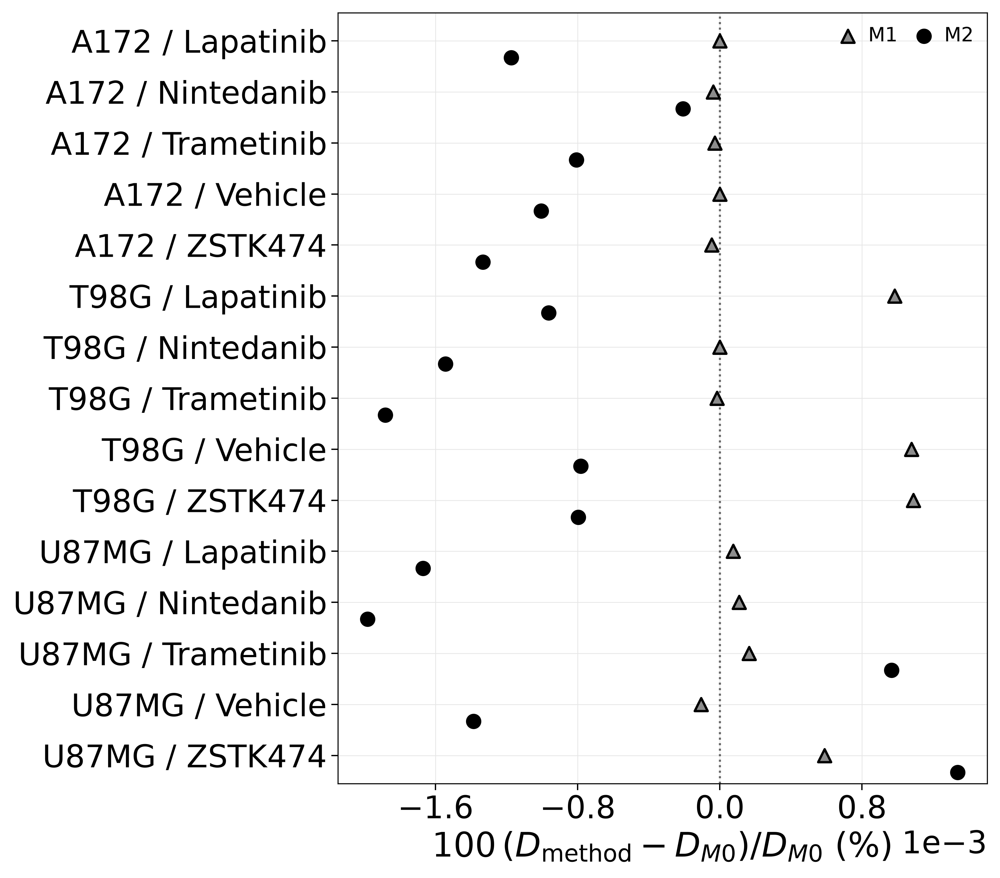

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_effect_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_effect_replicate_1')

In [21]:
plot_figure1('normalized_mse', 'replicate_1', effect=True)


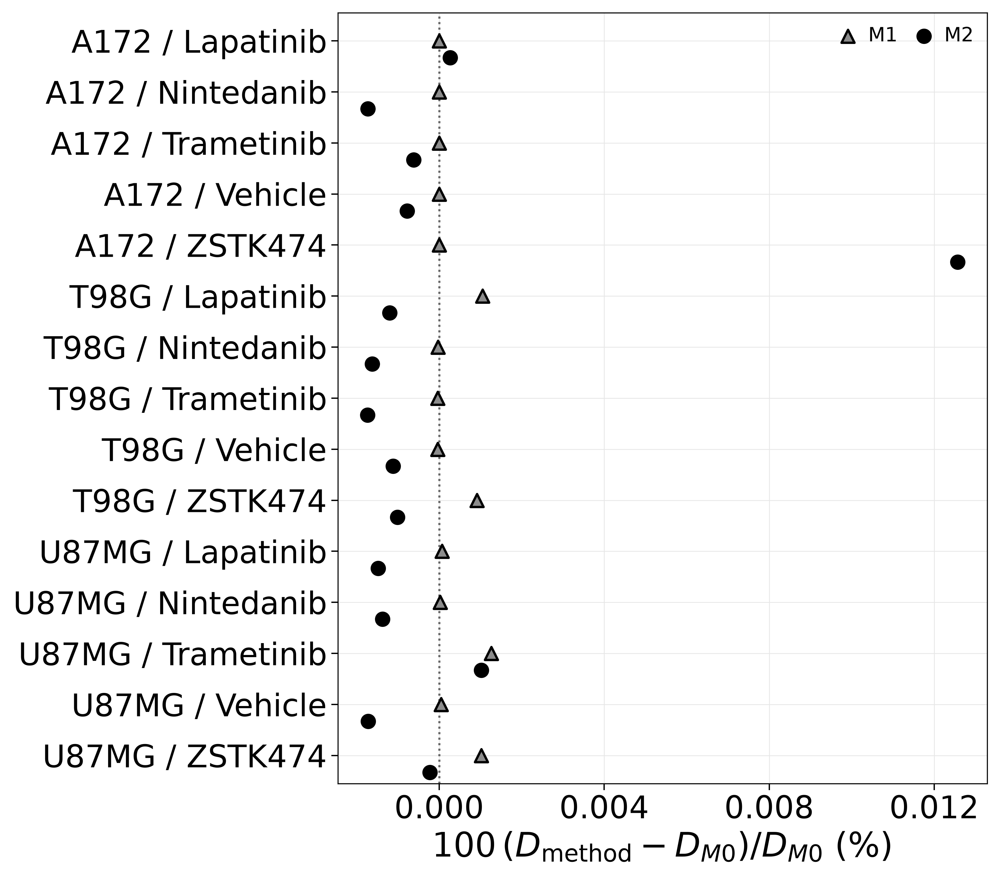

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_effect_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure1_secondary_effect_replicate_2')

In [22]:
plot_figure1('normalized_mse', 'replicate_2', effect=True)


In [ ]:
FIGURE2_PRIMARY_STYLE = dict(
    ticksize=24,
    labelsize=28,
    legend_size=20,
    annotation_size=20,
    panel_title_size=10.8,

    marker_size=100,
    line_width=3,
    show_null_parameter_note=True,

    figure2_legend_transparent=True,
    figure2_legend_y=0.01,
    figure2_legend_x_margin=0.015,
    figure2_legend_ncol=1,
    figure2_ylim_bottom=-0.42,

   
    figure_save_bbox_inches=None,   
    figsize=(10.4, 5.25),           
    combined_figsize=(23.0, 24.0), 
    
    figure2_single_margins=(0.12, 0.94, 0.235, 0.945),
    figure2_combined_margins=(0.067, 0.985, 0.068, 0.945),
    figure2_wspace=0.28,            
    figure2_hspace=0.57,            
    figure2_title_pad=7,
    figure2_panel_letters=False,    
    figure2_panel_letter_size=19,
)

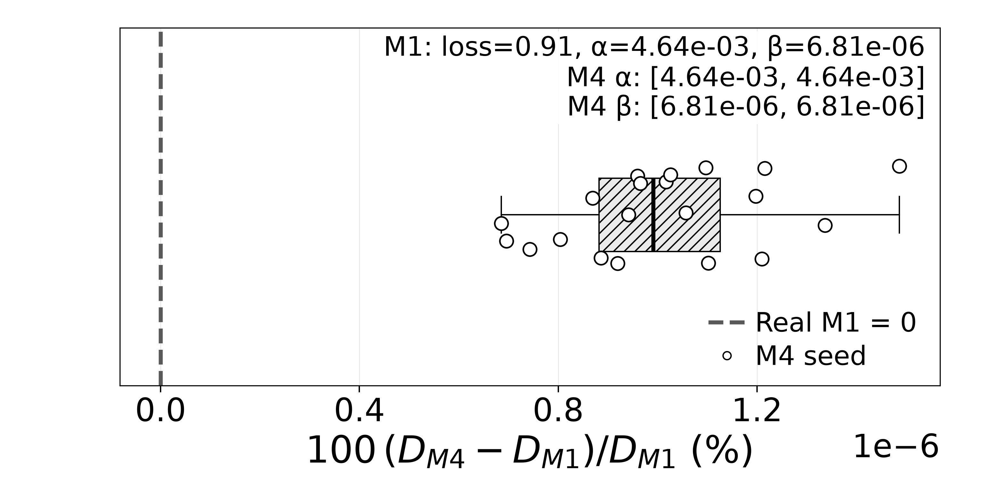

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Lapatinib_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Lapatinib_replicate_1')

In [25]:
plot_figure2('A172', 'Lapatinib', 'replicate_1')


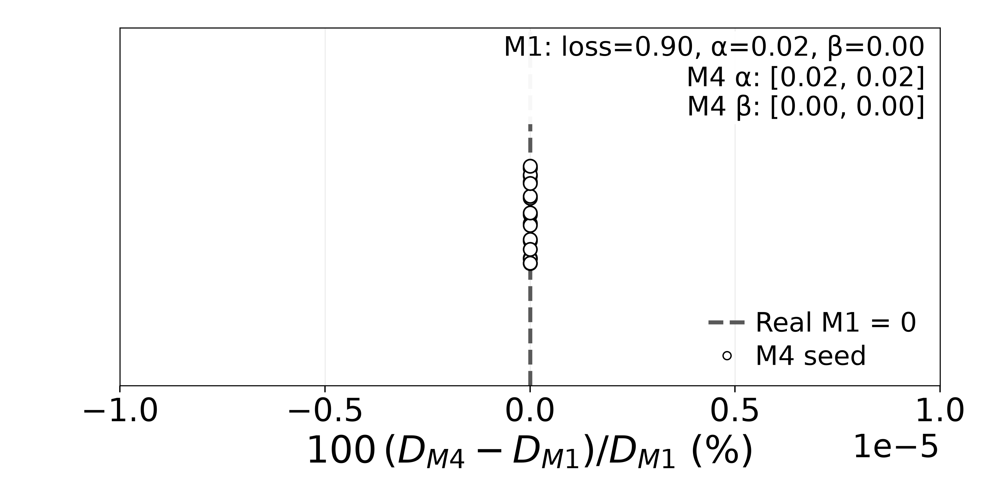

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Lapatinib_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Lapatinib_replicate_2')

In [26]:
plot_figure2('A172', 'Lapatinib', 'replicate_2')


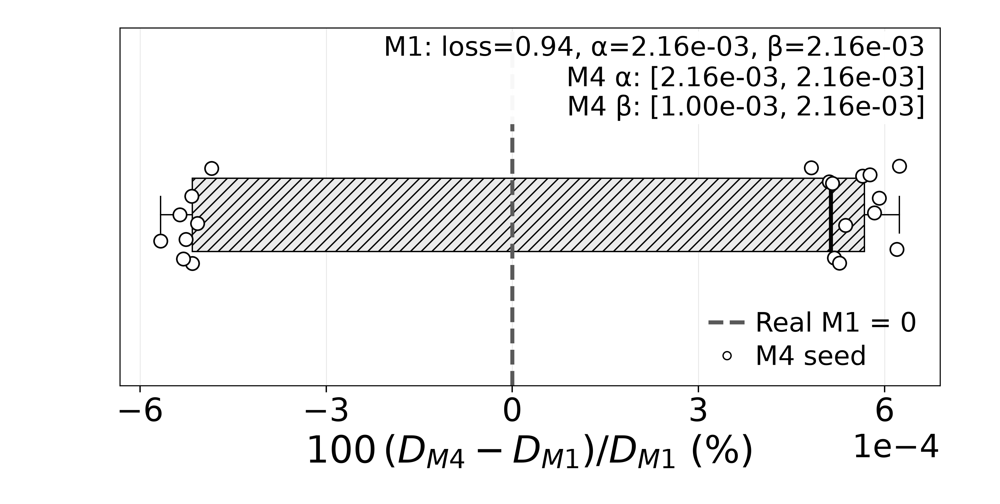

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Trametinib_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Trametinib_replicate_1')

In [27]:
plot_figure2('A172', 'Trametinib', 'replicate_1')


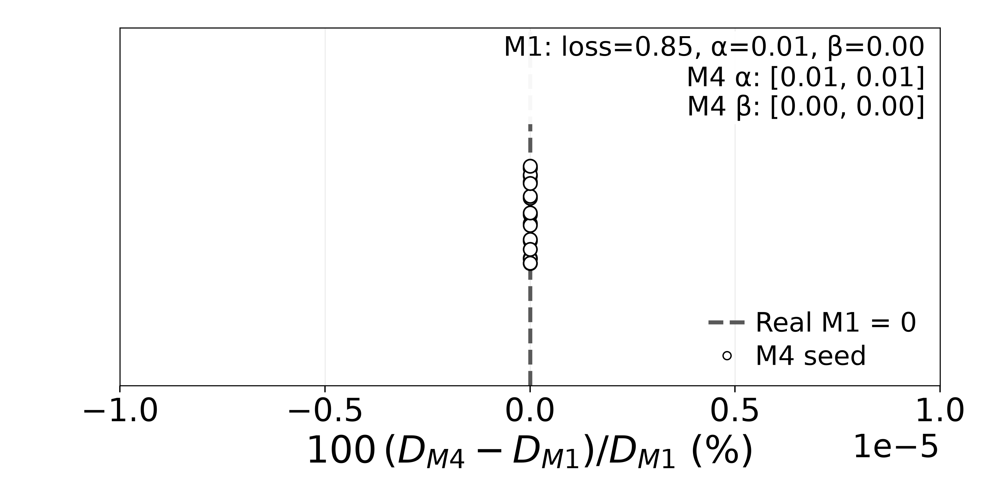

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Trametinib_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_A172_Trametinib_replicate_2')

In [28]:
plot_figure2('A172', 'Trametinib', 'replicate_2')


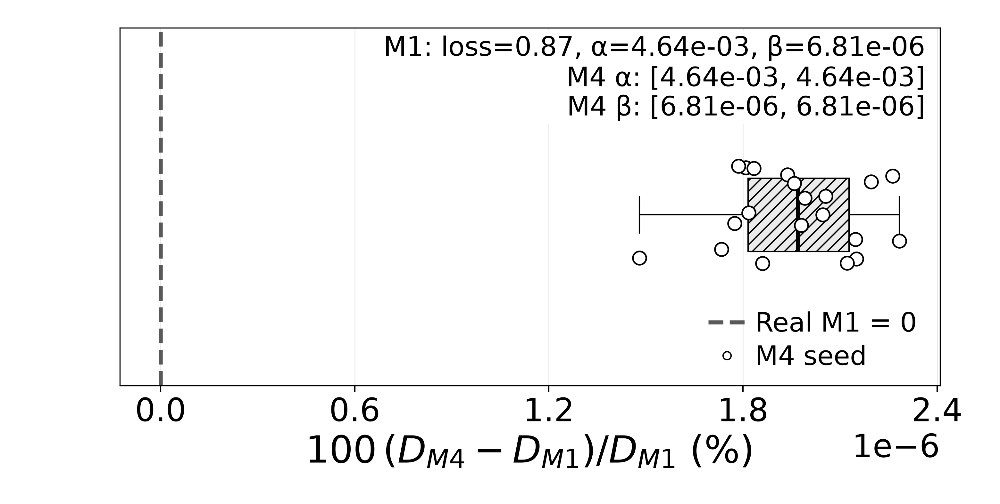

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_T98G_Nintedanib_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_T98G_Nintedanib_replicate_1')

In [29]:
plot_figure2('T98G', 'Nintedanib', 'replicate_1')


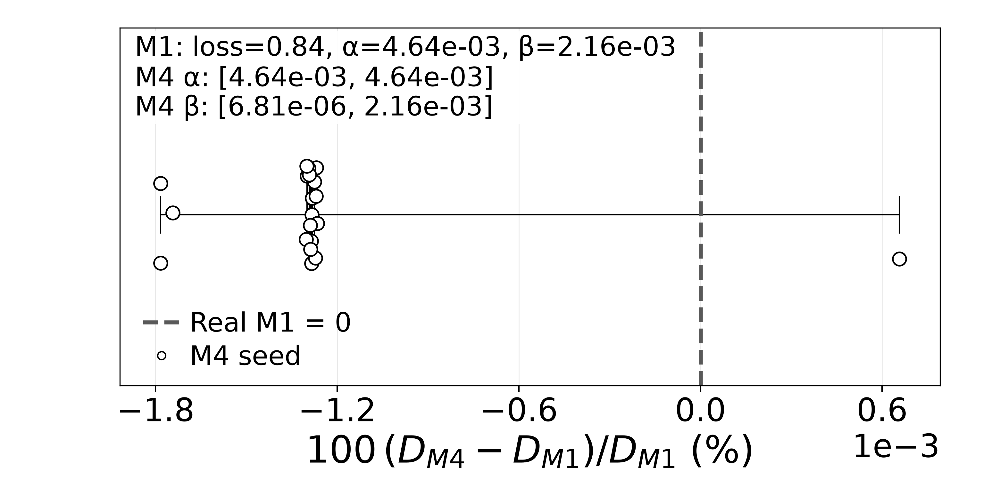

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_T98G_Nintedanib_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_T98G_Nintedanib_replicate_2')

In [30]:
plot_figure2('T98G', 'Nintedanib', 'replicate_2')


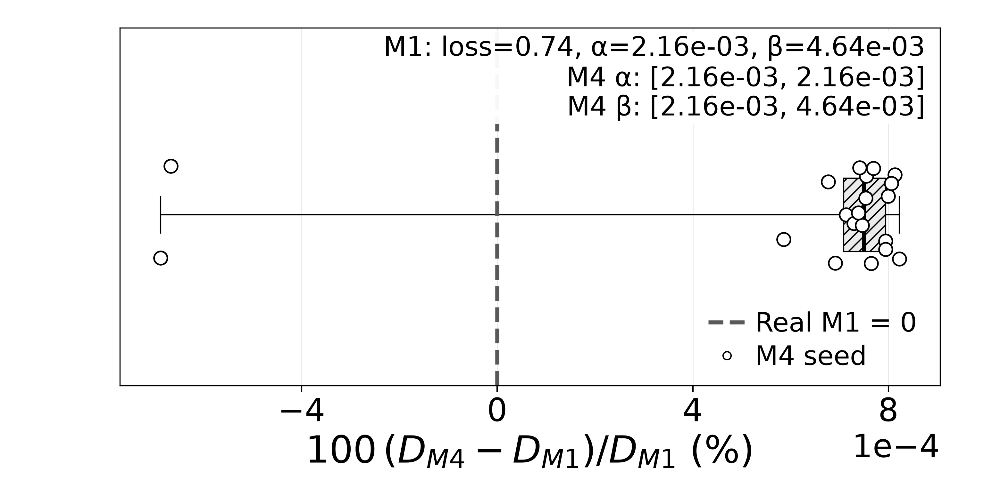

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_U87MG_ZSTK474_replicate_1


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_U87MG_ZSTK474_replicate_1')

In [31]:
plot_figure2('U87MG', 'ZSTK474', 'replicate_1')


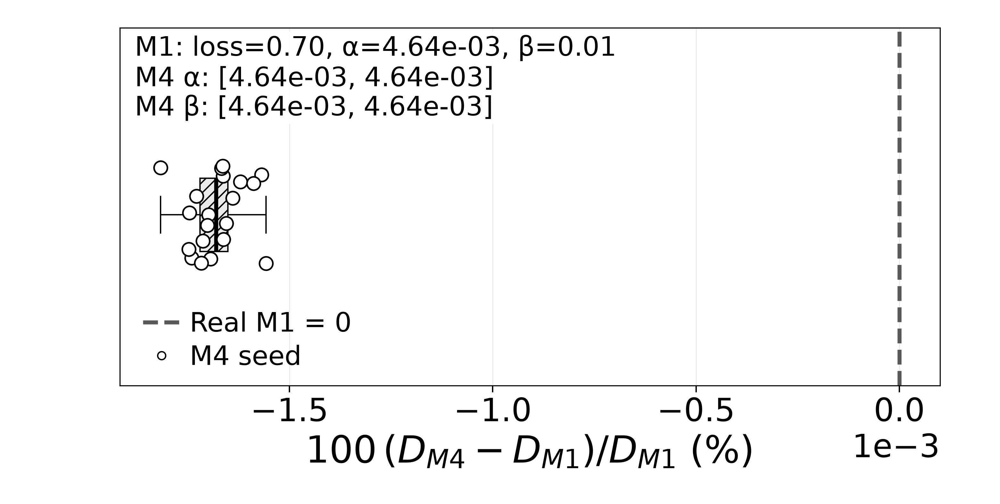

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_U87MG_ZSTK474_replicate_2


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure2_primary_U87MG_ZSTK474_replicate_2')

In [32]:
plot_figure2('U87MG', 'ZSTK474', 'replicate_2')


In [ ]:
FIGURE3_PRIMARY_STYLE = dict(
    ticksize=28,
    labelsize=30,
    legend_size=9,
    annotation_size=9,
    panel_title_size=11,

    marker_size=100,
    line_width=3,

    figure3_paired_quantiles=(0.0, 1.0),
    figure3_paired_marker_size=144,

    figure3_replicate_offsets={
        'replicate_1': -0.25,
        'replicate_2':  0.25,
    },

    figure3_model_offset=0.125,

    figure3_audit_circle_size=225,
    figure3_audit_diamond_size=169,
    figure3_audit_edge_width=1.6,

    figure3_audit_quantiles=(0.05, 0.95),

    figsize=(10, 17),
    figure3_paired_figsize=(10, 10),

    combined_figsize=(17.2, 42),
    figure3_combined_height_ratios=(0.45, 1.30, 1.30),
)

### Figure 3：legend 转入 LaTeX caption（图中不绘制 legend）

```latex
\caption{Adaptive attenuation across the 15 cell-line/drug contexts, evaluated using held-out Poisson deviance.
In the paired-effect panel, circles mark the mean seed-paired M2--M3 relative effect, and horizontal segments span the observed minimum--maximum range across the 20 paired seeds.
In the four audit panels, circles denote the M2 value, diamonds denote the mean across 20 M3 seeds, and horizontal segments indicate the 5th--95th percentile range of the M3 seed values.
Filled symbols and solid horizontal segments correspond to \texttt{replicate\_1}; open symbols and dashed horizontal segments correspond to \texttt{replicate\_2}.
The dotted vertical line in the paired-effect panel indicates zero relative effect.
These horizontal ranges describe variation across saved seeds and are not biological confidence intervals.
Replicate labels designate evaluation labels and do not imply independent biological replicates.}
```

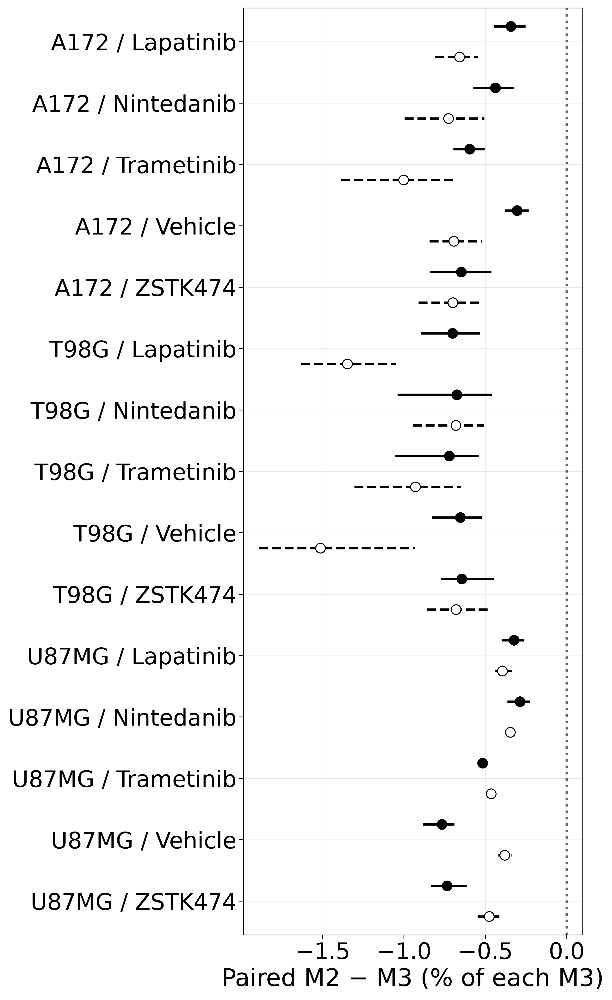

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_paired_effect


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_paired_effect')

In [35]:
plot_figure3('paired_effect')


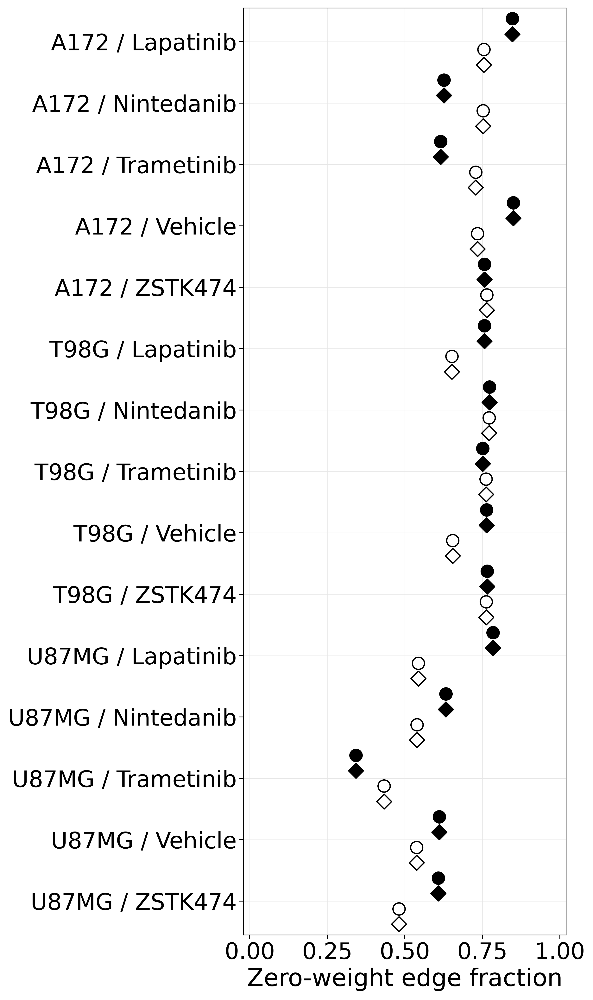

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_zero_fraction


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_zero_fraction')

In [36]:
plot_figure3('zero_fraction')


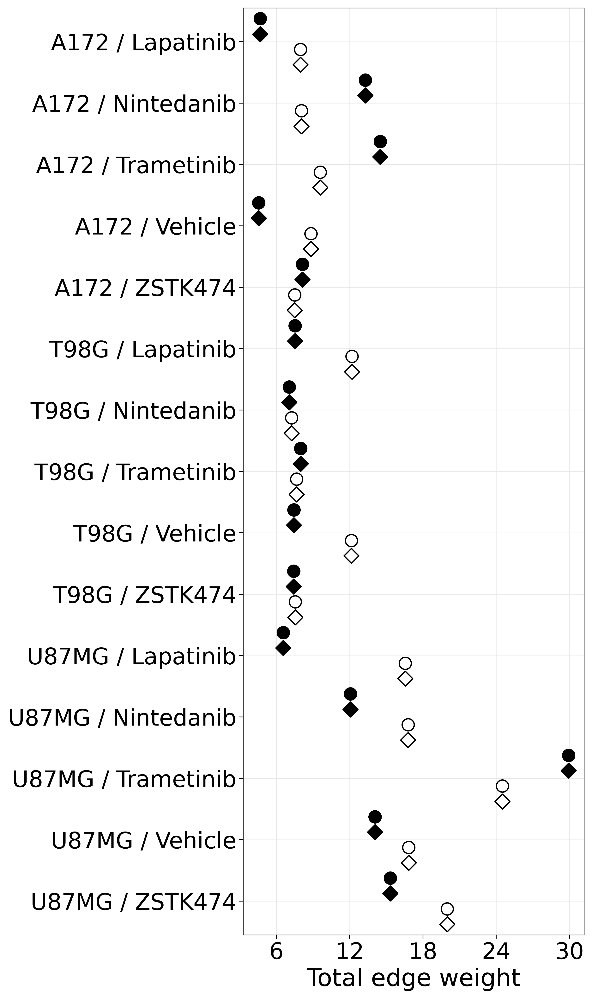

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_weight_sum


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_weight_sum')

In [37]:
plot_figure3('weight_sum')


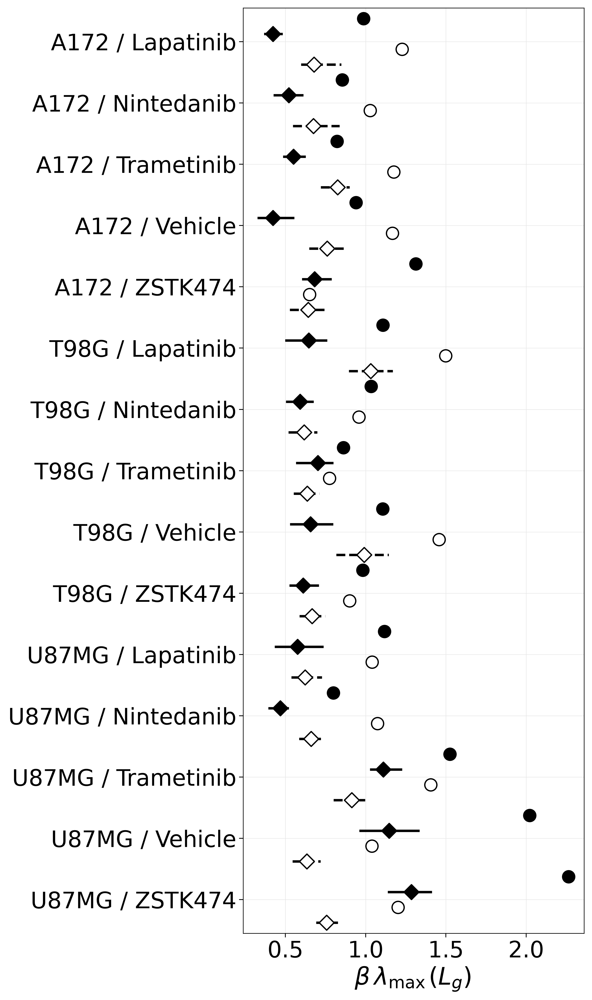

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_gene_scale


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_gene_scale')

In [38]:
plot_figure3('gene_scale')


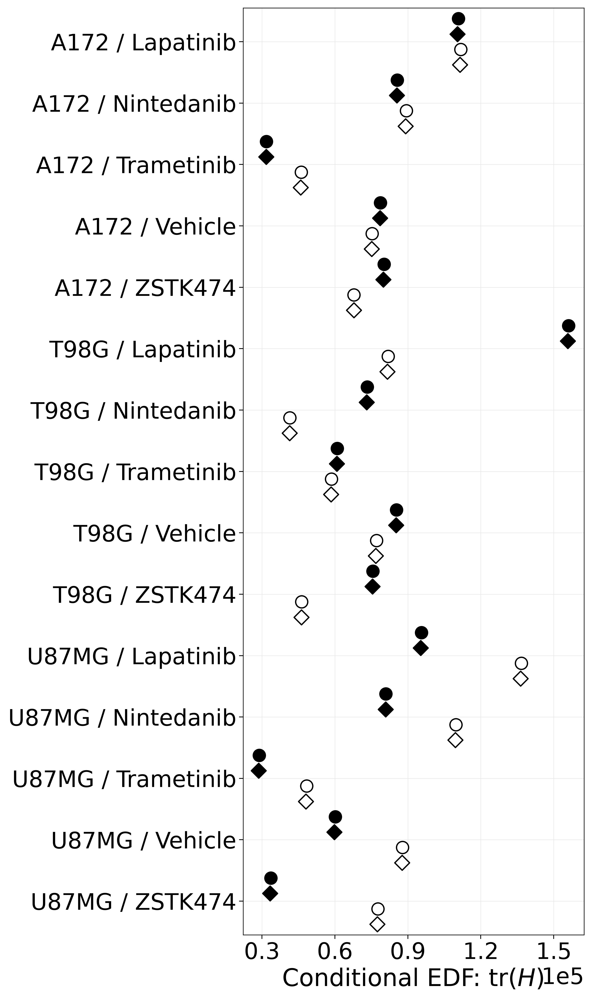

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_conditional_EDF


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure3_primary_conditional_EDF')

In [39]:
plot_figure3('conditional_EDF')


In [ ]:
FIGURE4_PRIMARY_STYLE = dict(
    ticksize=26,
    labelsize=28,

    annotation_size=22,
    context_key_size=22,
    legend_size=24,
    panel_title_size=12,

    marker_size=100,
    edge_width=1.0,

    context_key_width=1.0,
    figure4_key_height_share=0.70,
    figure4_key_linespacing=1.12,

    adaptive_limits=(-0.015, 0.015),
    context_label_radius=(
        12, 20, 32, 44, 58,
        74, 96, 120, 150, 175
    ),
    show_context_numbers=True,

    figure4_plain_ticks=True,
    figure4_tick_nbins=4,
    figure4_adaptive_tick_count=3,
    figure4_xlabel_pad=18,

    figsize=(14.0, 9.2),
    combined_figsize=(20.5, 9.5),
)

### Figure 4：outlier #5 的 LaTeX caption 说明

```latex
\caption{Label consistency for held-out Poisson deviance across the 15 contexts listed in the context key. The left panel shows the fixed M1--M0 relative effect (denominator M0); the right shows adaptive M2--M1 (denominator M1). The identity line is dashed, the horizontal and vertical solid lines indicate zero, and shaded bands mark the predeclared near-zero region. The adaptive panel uses \(x,y\in[-0.015,\,0.015]\%\) to magnify the main cluster. Context 5 (A172/ZSTK474) is a prominent outlier lying outside this zoom, so it is intentionally omitted from the right-hand plot but retained in the underlying data and in the context key. Context numbers are label identifiers, not seed indices; the two labels are not independent biological replicates.}
```

### Figure4_primary_fixed


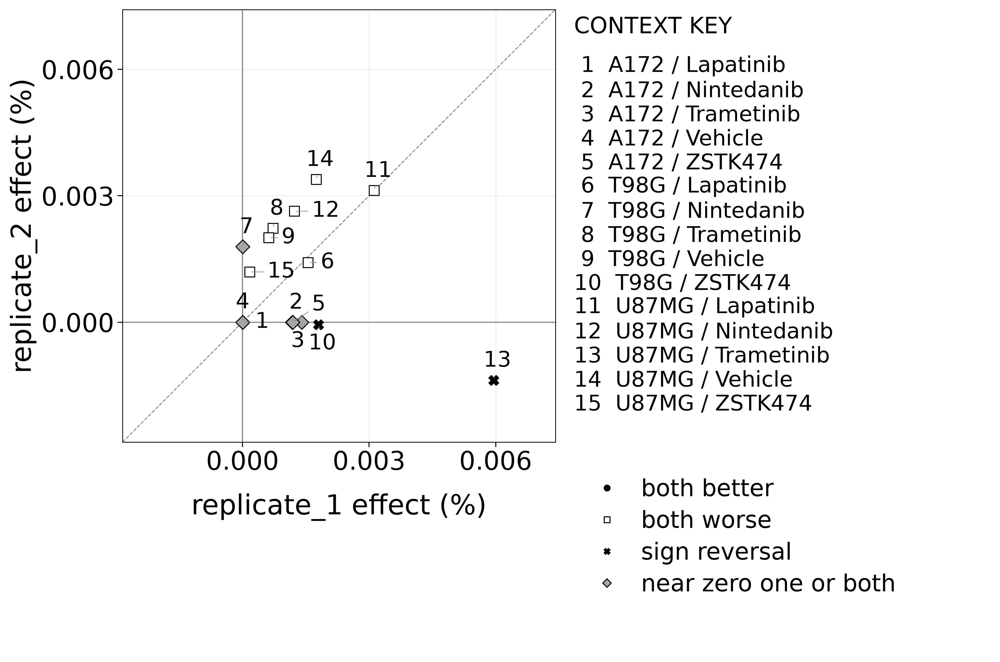

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure4_primary_fixed


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure4_primary_fixed')

In [42]:
plot_figure4('fixed')


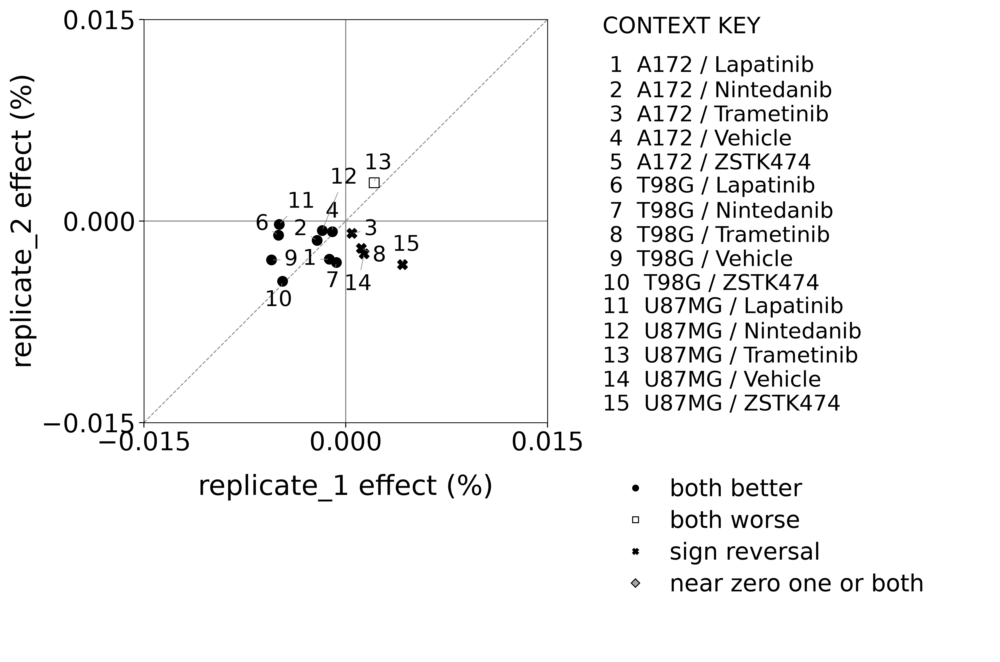

已保存： /home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure4_primary_adaptive


PosixPath('/home/featurize/work/biological_prior_validation/YifengMu_Figures/Figure4_primary_adaptive')

In [43]:
plot_figure4('adaptive')
